In [1]:
# The following is to know when this notebook has been run and with which python version.
import time, sys
print(time.ctime())
print(sys.version.split('|')[0])

Tue Mar 24 15:21:50 2026
3.13.2 


This is part of the Python lecture given by Christophe Morisset at IA-UNAM. More informations at: http://python-astro.blogspot.mx/


# D: How to make plots, images, 3D, etc, using Matplotlib

In [2]:
# this allows the plots to appear in the Notebook webpage:
# NOT NEEDED ANYMORE!!!
# %matplotlib inline  
import numpy as np
import matplotlib.pyplot as plt # this is the plotting library

Very well done tutorials on the mail Matplotlib web page: http://matplotlib.org/

## Simple plot

 In the following cell, we plot a function

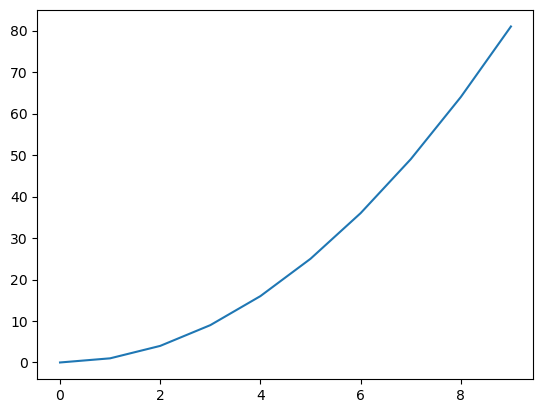

In [3]:
# Just to convince that things are easy:
x = np.arange(10) # define an array
plt.plot(x, x**2); # so quickly plotted... Notice the ";" at the end of the line -> ;

## Controling colors and symbols

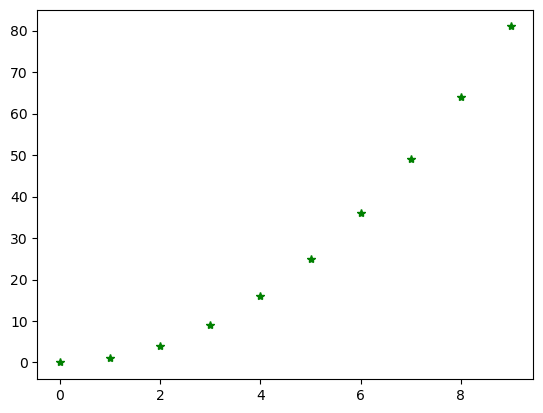

In [4]:
plt.plot(x, x**2, '*g');

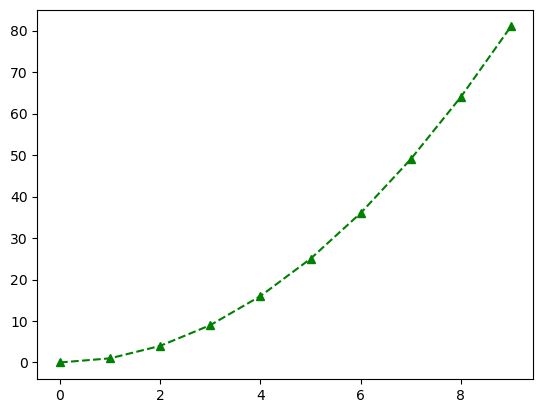

In [5]:
plt.plot(x, x**2, c='green', marker='^', linestyle='--');

In [6]:
import matplotlib
print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline


In [7]:
# To illustrate the possibilities of the interactive window:
#%matplotlib tk

# The following needs to instal ipympl, and to update using pip both ipympl and ipywidgets 
# !conda install -y -c conda-forge ipympl ipywidgets
#%matplotlib widget 

# The following is to intersact with the plots in a separate window, works on MacOS
#%matplotlib osx 

#matplotlib.use('qtagg')
#matplotlib.use('TkAgg') # or TkAgg', 'Qt5Agg', 'MacOSX', etc.

# See: https://matplotlib.org/stable/users/explain/figure/backends.html



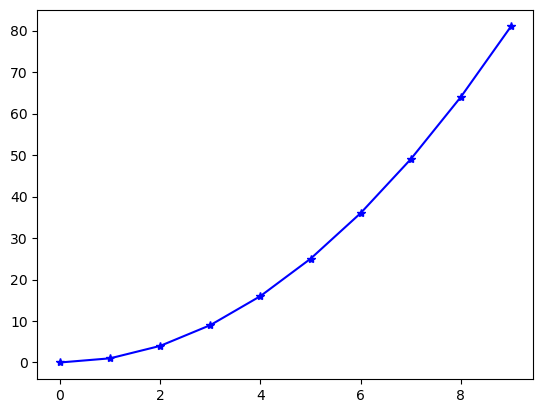

In [8]:
x = np.arange(10) # define an array
plt.plot(x, x**2, '*b', linestyle='-') ;

In [9]:
# Back to the inline graphics mode !!!Does not work anymore!!! Need to restart de kernel.
#%matplotlib module://matplotlib_inline.backend_inline
#get_ipython().run_line_magic('matplotlib', 'inline')

## Overplot

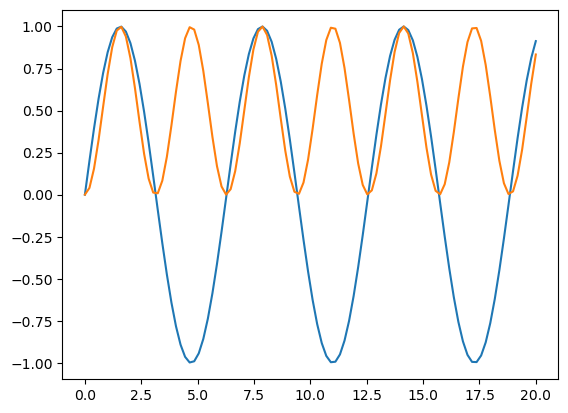

In [10]:
x = np.linspace(0, 20, 100)  # 100 evenly-spaced values from 0 to 20
y = np.sin(x)

plt.plot(x, y)
plt.plot(x, y**2); # overplot by default;

## Fixing axes limits

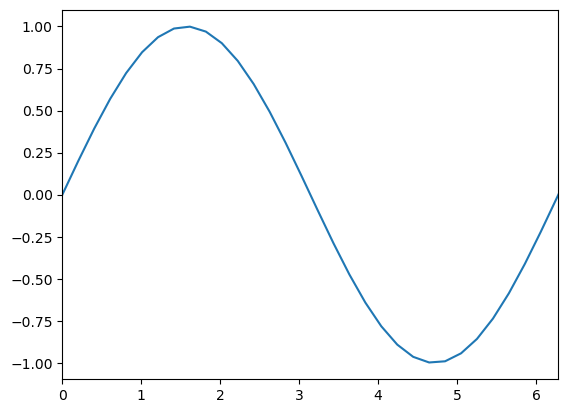

In [11]:
plt.plot(x, y)
plt.xlim(0., np.pi*2); # Take care, it's NOT plt.xlim = (1, 2), this would ERASE the xlim method from plt!!!;

## Labels, titles

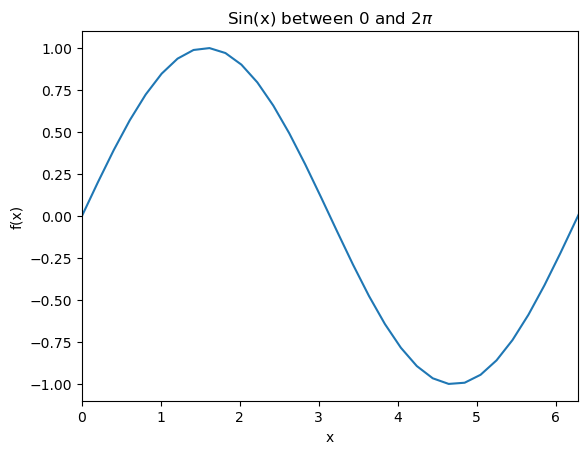

In [12]:
plt.plot(x, y)
plt.xlim((0., np.pi*2))
plt.title(r'Sin(x) between 0 and $2\pi$')
plt.xlabel('x')
plt.ylabel('f(x)');

## plot method documentation

In [13]:
help(plt.plot)

Help on function plot in module matplotlib.pyplot:

plot(
    *args: 'float | ArrayLike | str',
    scalex: 'bool' = True,
    scaley: 'bool' = True,
    data=None,
    **kwargs
) -> 'list[Line2D]'
    Plot y versus x as lines and/or markers.

    Call signatures::

        plot([x], y, [fmt], *, data=None, **kwargs)
        plot([x], y, [fmt], [x2], y2, [fmt2], ..., **kwargs)

    The coordinates of the points or line nodes are given by *x*, *y*.

    The optional parameter *fmt* is a convenient way for defining basic
    formatting like color, marker and linestyle. It's a shortcut string
    notation described in the *Notes* section below.

    >>> plot(x, y)        # plot x and y using default line style and color
    >>> plot(x, y, 'bo')  # plot x and y using blue circle markers
    >>> plot(y)           # plot y using x as index array 0..N-1
    >>> plot(y, 'r+')     # ditto, but with red plusses

    You can use `.Line2D` properties as keyword arguments for more
    control on th

## Legends

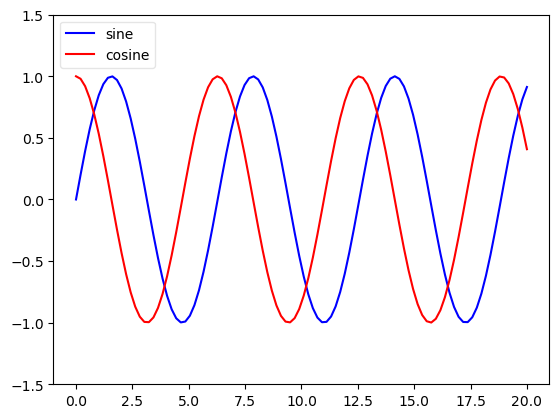

In [14]:
x = np.linspace(0, 20, 100)
y1 = np.sin(x)
y2 = np.cos(x)

plt.plot(x, y1, '-b', label='sine')
plt.plot(x, y2, '-r', label='cosine')
plt.legend(loc='upper left', fancybox=True, framealpha=0.5)
plt.ylim((-1.5, 1.5));

## Object oriented way

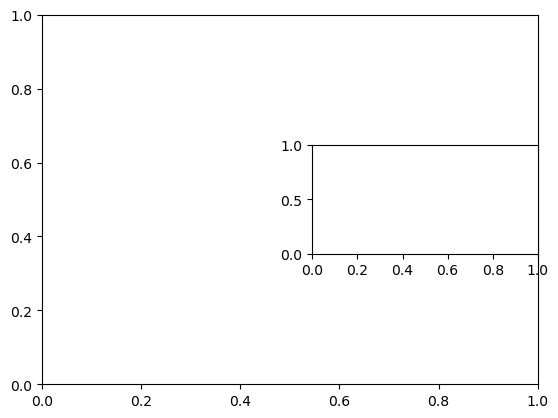

In [15]:
fig = plt.figure()  # a new figure window
ax = fig.add_subplot(1,1,1)  # specify (nrows, ncols, axnum)
ax2 = fig.add_subplot(3, 2, 4)  # specify (nrows, ncols, axnum)
# same as ax = fig.add_subplot()

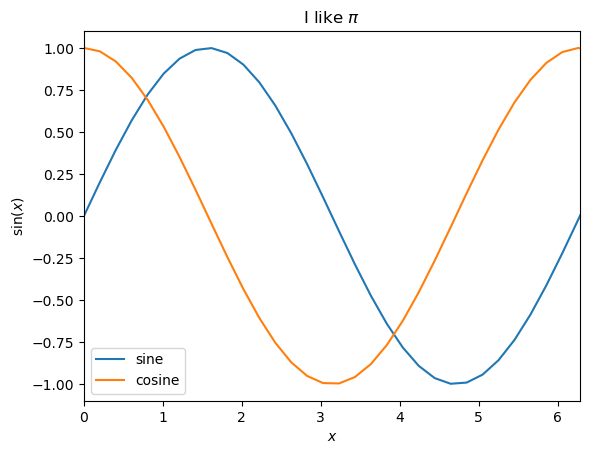

In [16]:
fig, ax = plt.subplots()  # one command way
ax.plot(x, y1)
ax.plot(x, y2)
ax.set_xlim(0., 2*np.pi)
ax.legend(['sine', 'cosine'], loc='best') # If the legends are not already defined in the plot call
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$\sin(x)$")
ax.set_title(r"I like $\pi$");

In [17]:
# The following outputs a HUGE quantity of information! I comment it for now
help(ax)

Help on Axes in module matplotlib.axes._axes object:

class Axes(matplotlib.axes._base._AxesBase)
 |  Axes(
 |      fig,
 |      *args,
 |      facecolor=None,
 |      frameon=True,
 |      sharex=None,
 |      sharey=None,
 |      label='',
 |      xscale=None,
 |      yscale=None,
 |      box_aspect=None,
 |      forward_navigation_events='auto',
 |      **kwargs
 |  )
 |
 |  An Axes object encapsulates all the elements of an individual (sub-)plot in
 |  a figure.
 |
 |  It contains most of the (sub-)plot elements: `~.axis.Axis`,
 |  `~.axis.Tick`, `~.lines.Line2D`, `~.text.Text`, `~.patches.Polygon`, etc.,
 |  and sets the coordinate system.
 |
 |  Like all visible elements in a figure, Axes is an `.Artist` subclass.
 |
 |  The `Axes` instance supports callbacks through a callbacks attribute which
 |  is a `~.cbook.CallbackRegistry` instance.  The events you can connect to
 |  are 'xlim_changed' and 'ylim_changed' and the callback will be called with
 |  func(*ax*) where *ax* is the

## log plots

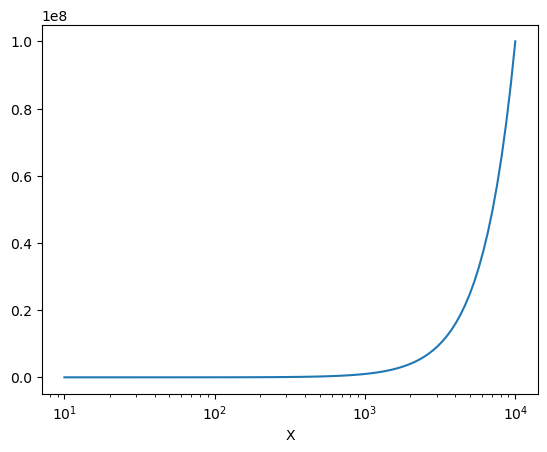

In [18]:
xl = np.logspace(1, 4, 100)
fig, ax = plt.subplots()
ax.semilogx(xl, xl**2)
ax.set_xlabel('X');

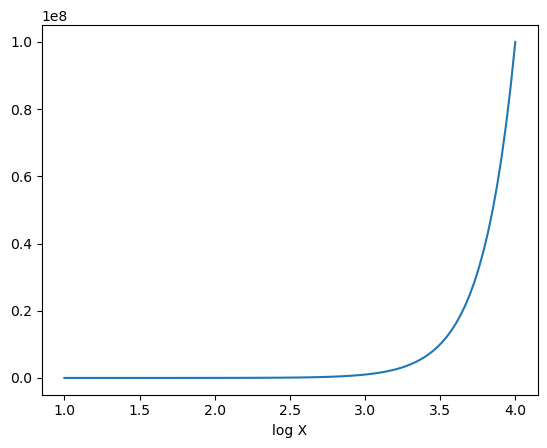

In [19]:
fig, ax = plt.subplots()
ax.plot(np.log10(xl), xl**2)
ax.set_xlabel('log X');

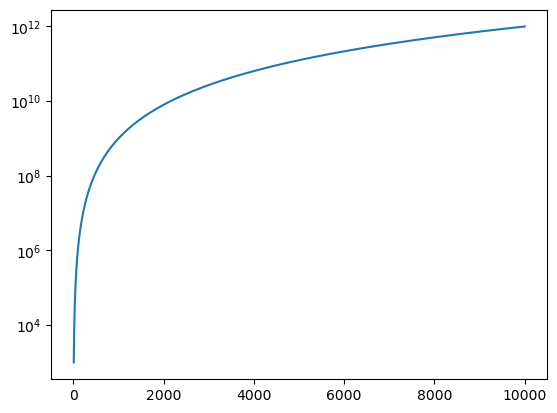

In [20]:
fig, ax = plt.subplots()
ax.semilogy(xl, xl**3);

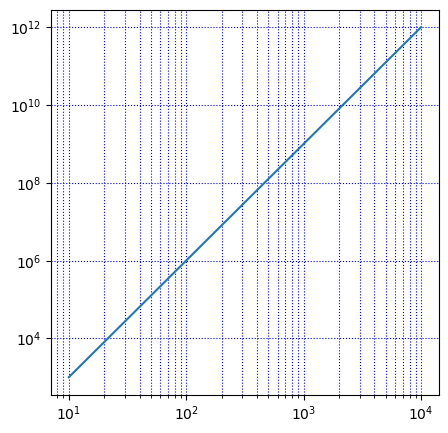

In [21]:
fig, ax = plt.subplots(figsize=(5,5))
ax.loglog(xl, xl**3)
ax.grid(which="both",ls=":", c='blue');

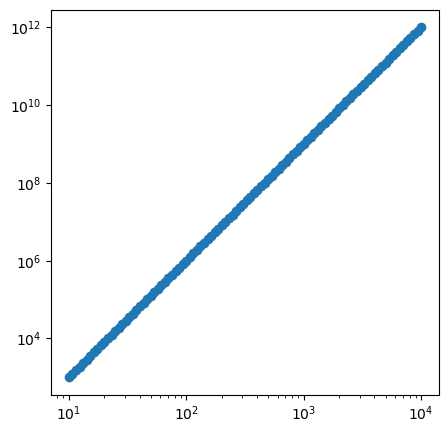

In [22]:
# log axes can be defined after the plot
fig, ax = plt.subplots(figsize=(5,5))
ax.plot(xl, xl**3, marker='o')
ax.set_yscale('log')
ax.set_xscale('log')

## Scatter

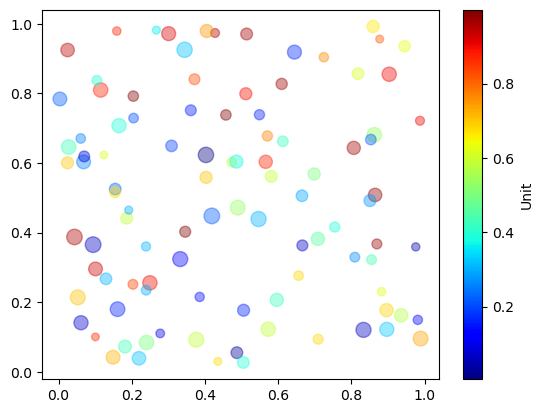

In [23]:
N = 100
xr = np.random.rand(N)
yr = np.random.rand(N)
cr = np.random.rand(N)
sr = np.random.rand(N)

fig, ax = plt.subplots()
sc = ax.scatter(xr, yr, c=cr, s=30 + sr*100, edgecolor=None, alpha=0.4, cmap='jet'); # Sizes and colors depend on valyues of other variables
cb = fig.colorbar(sc)
cb.solids.set(alpha=1) 
cb.set_label('Unit');

## multiple plots

(2, 3) <class 'numpy.ndarray'>


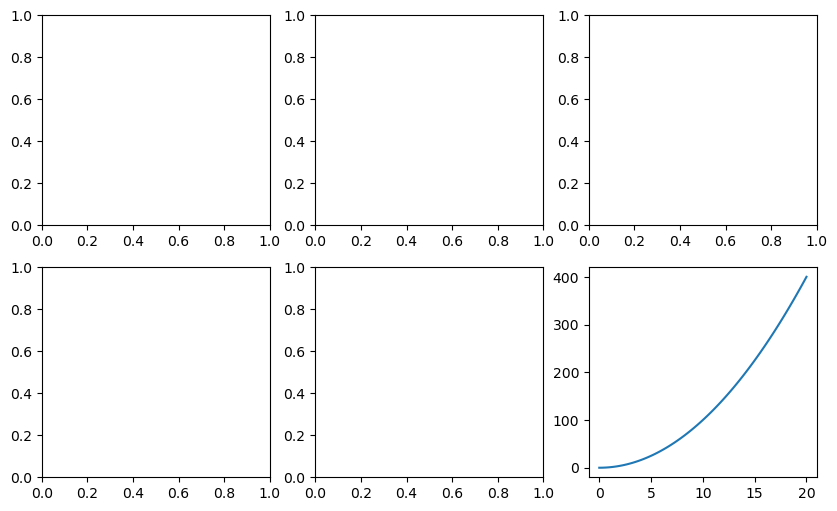

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(10,6)) # row, column
print(axes.shape, type(axes))
axes[1,2].plot(x,x**2); # [row, column]

In [25]:
axes # numpy table of axes, with 2 rows and 3 columns, each element is an axis object.

array([[<Axes: >, <Axes: >, <Axes: >],
       [<Axes: >, <Axes: >, <Axes: >]], dtype=object)

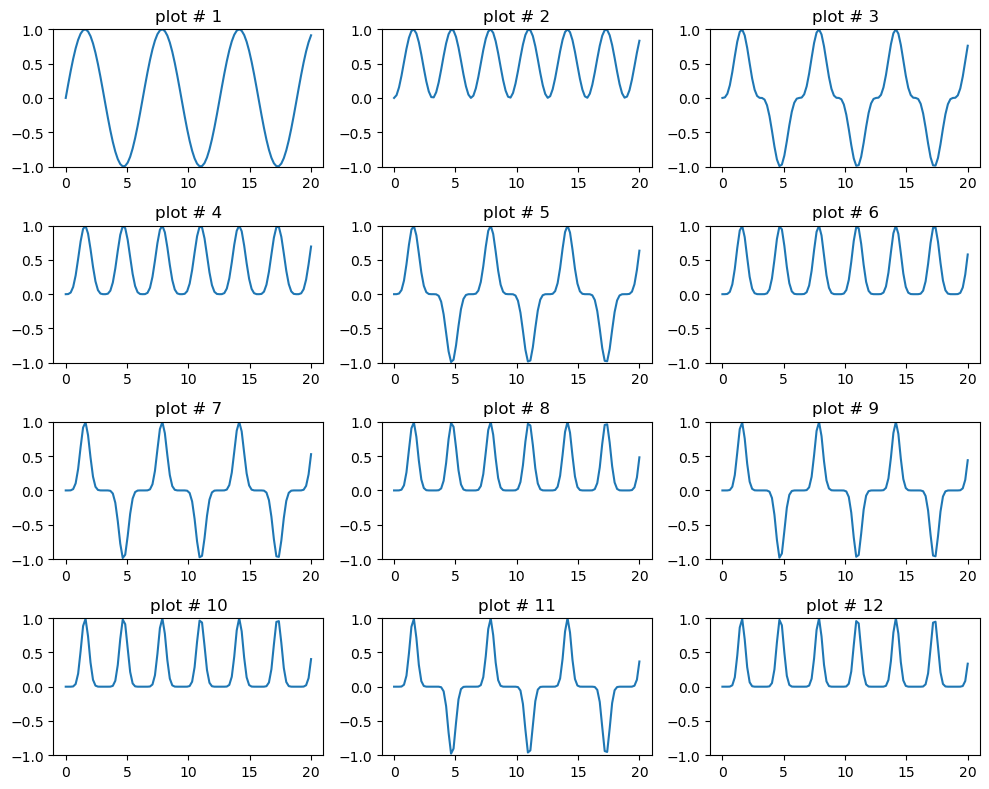

In [26]:
x = np.linspace(0, 20, 100)
y1 = np.sin(x)

fig, axes = plt.subplots(4, 3, figsize=(10,8)) # 4 rows , 3 columns -> 12 subplots
for i, ax in enumerate(axes.ravel()): # axes is a 2D array.. Need to ravel it to run over every ax
    ax.set_title(f'plot # {i+1}')
    ax.plot(x, y1**(i+1))
    ax.set_ylim((-1, 1))
fig.tight_layout() # Better output

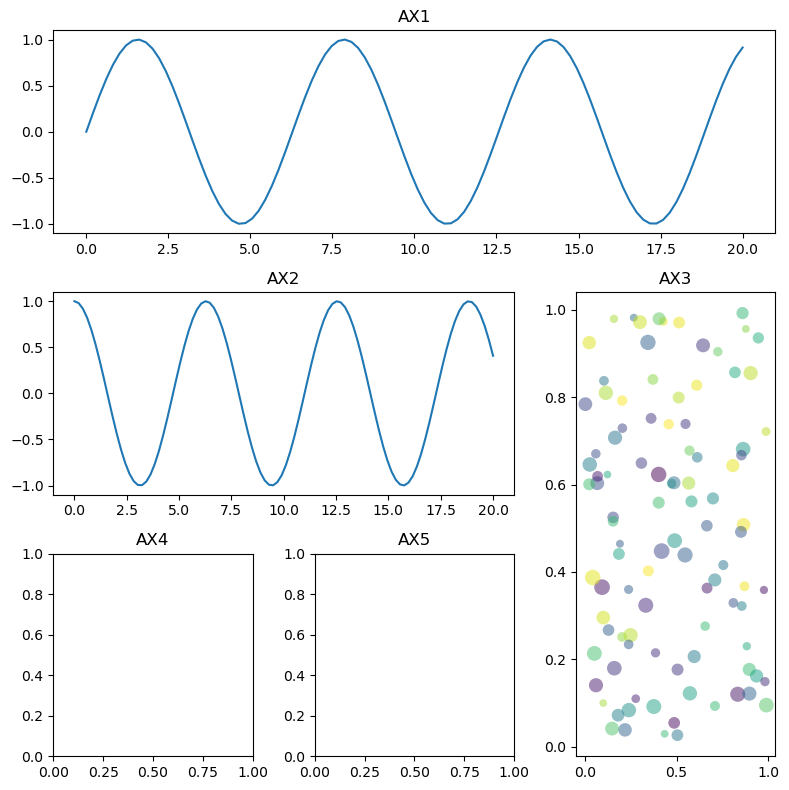

In [27]:
fig = plt.figure(figsize=(8, 8))
gs = plt.GridSpec(3, 3) # 3x3 grid -> 9 places to put plots
ax1 = fig.add_subplot(gs[0, :]) 
ax2 = fig.add_subplot(gs[1, :2])
ax3 = fig.add_subplot(gs[1:, 2])
ax4 = fig.add_subplot(gs[2, 0]) # 3rd row, 1rst column 
ax5 = fig.add_subplot(gs[2, 1])

ax1.plot(x, y1)
ax1.set_title('AX1')

ax2.plot(x, y2)
ax2.set_title('AX2')

ax3.scatter(xr, yr, c=cr, s=30+sr*100, edgecolor='none', alpha=0.5)
ax3.set_title('AX3')

ax4.set_title('AX4')

ax5.set_title('AX5')

fig.tight_layout();
#etc...

## Order of the commands

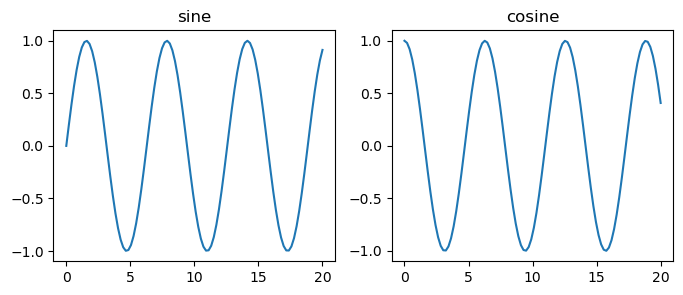

In [28]:
fig1 = plt.figure(figsize=(8, 3))

ax1 = fig1.add_subplot(1, 2, 1)
ax1.plot(x, np.sin(x))
ax1.set_title('sine')

ax2 = fig1.add_subplot(1, 2, 2)
ax2.plot(x, np.cos(x))
ax2.set_title('cosine');

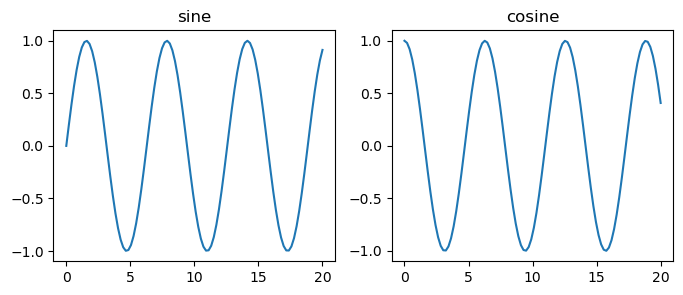

In [29]:
fig1 = plt.figure(figsize=(8, 3))
ax1 = fig1.add_subplot(1, 2, 1)
ax2 = fig1.add_subplot(1, 2, 2)

ax1.plot(x, np.sin(x))
ax2.plot(x, np.cos(x))

ax1.set_title('sine') # you can go back to change ax1 and ax2 after plotting
ax2.set_title('cosine'); # They both are objects containing method to apply on them;

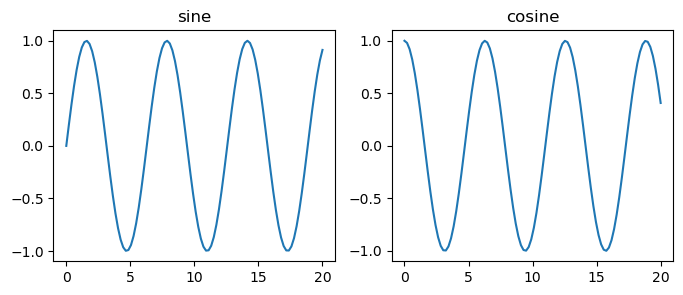

In [30]:
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
# fig, axes = plt.subplots(1, 2, figsize=(8, 3))
# ax1 = axes[0]
# ax2 = axes[1]

ax1.plot(x, np.sin(x))
ax2.plot(x, np.cos(x))

ax1.set_title('sine') # you can go back to change ax1 and ax2 after plotting
ax2.set_title('cosine'); # They both are objects containing method to apply on them

## Everything is object

<class 'list'>
1
<class 'matplotlib.lines.Line2D'>


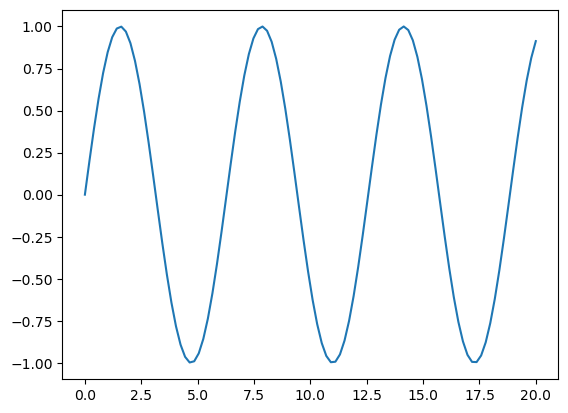

In [31]:
fig, ax = plt.subplots()
lines = ax.plot(x, np.sin(x))
print(type(lines))
print(len(lines))
print(type(lines[0]))

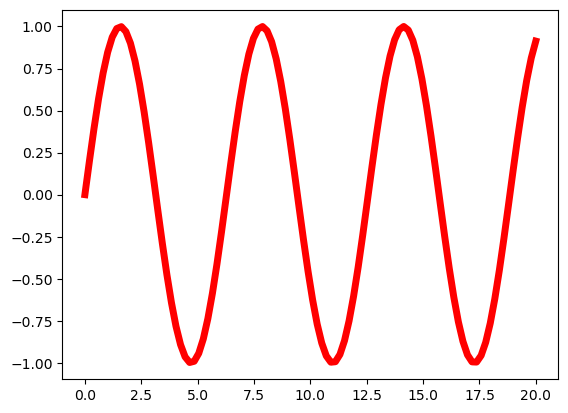

In [32]:
fig, ax = plt.subplots()
lines = ax.plot(x, np.sin(x))
line = lines[0]
#help(line) # HUGE quantity of information
line.set_color('red')
line.set_linewidth(5)
#fig.canvas.draw() # this is not necessary in notebook, but in scripts it is.

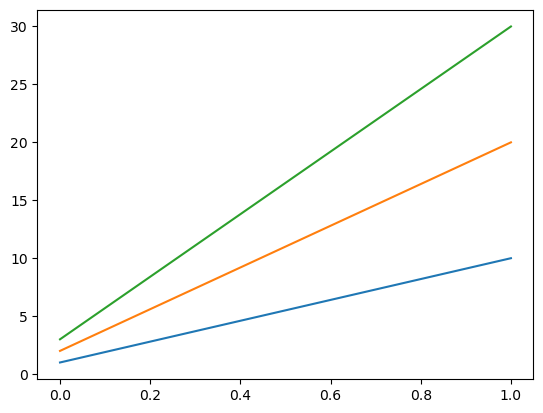

In [33]:
fig, ax = plt.subplots()
lines = ax.plot([[1,2,3],[10,20,30]])

[<matplotlib.lines.Line2D object at 0x118affd90>, <matplotlib.lines.Line2D object at 0x118affed0>, <matplotlib.lines.Line2D object at 0x118b38050>]
Plot using color C1
Plot using color C2
Plot using color C3


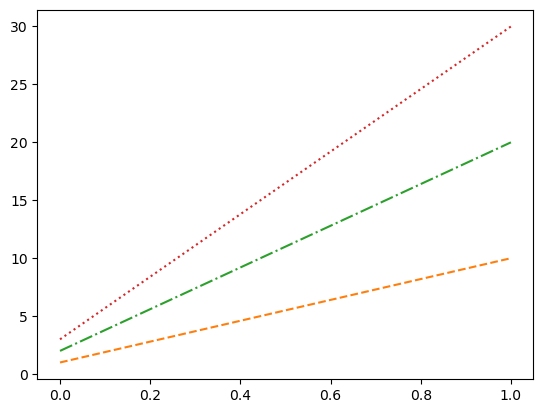

In [34]:
fig, ax = plt.subplots()
lines = ax.plot([[1,2,3],[10,20,30]])
print(lines)

line_styles = ('--', '-.', ':')

for i, line in enumerate(lines):
    color = f'C{i+1}'
    line.set_linestyle(line_styles[i])
    line.set_color(color)
    print(f'Plot using color {color}')


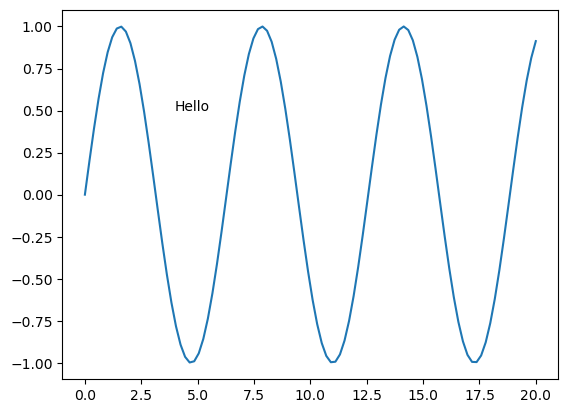

In [35]:
fig, ax = plt.subplots()
lines = ax.plot(x, np.sin(x))
ax.text(4, 0.5, "Hello");

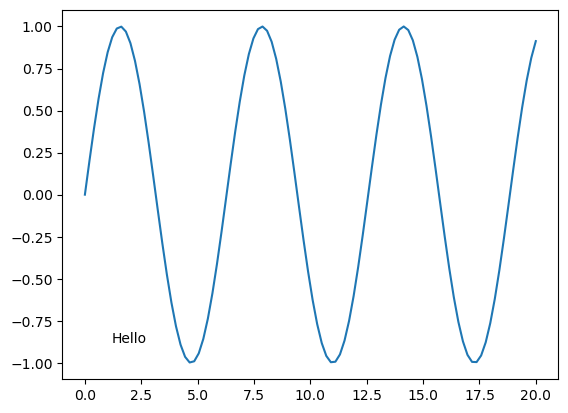

In [36]:
fig, ax = plt.subplots()
lines = ax.plot(x, np.sin(x))
#ax.set_xlim(-10,10)
ax.text(0.1, 0.1, "Hello", transform=ax.transAxes);

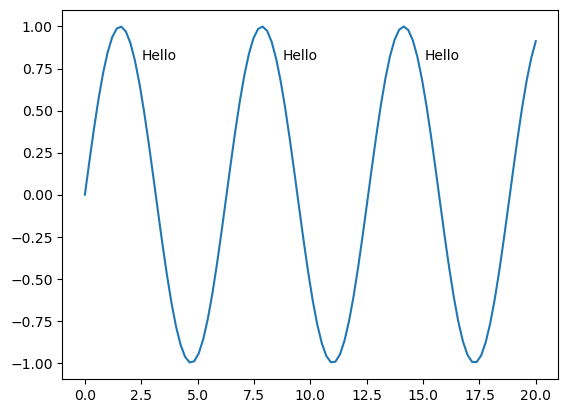

In [37]:
fig, ax = plt.subplots()
lines = ax.plot(x, np.sin(x))
for x_text in 2.5+2*np.pi*(np.arange(3)):
    ax.text(x_text, 0.8, "Hello")

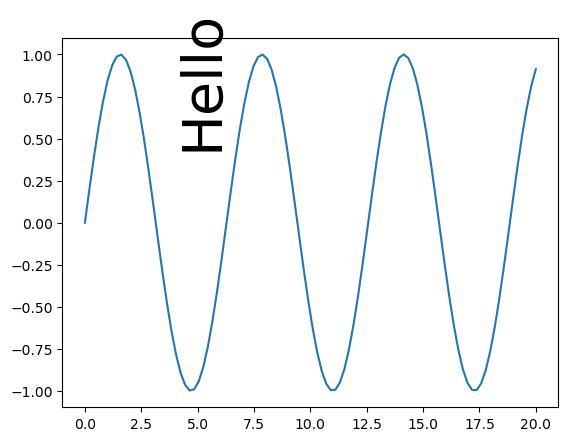

In [38]:
fig, ax = plt.subplots()
lines = ax.plot(x, np.sin(x))
txt = ax.text(4, 0.5, "Hello")
txt.set_rotation(90)
txt.set_size(40)

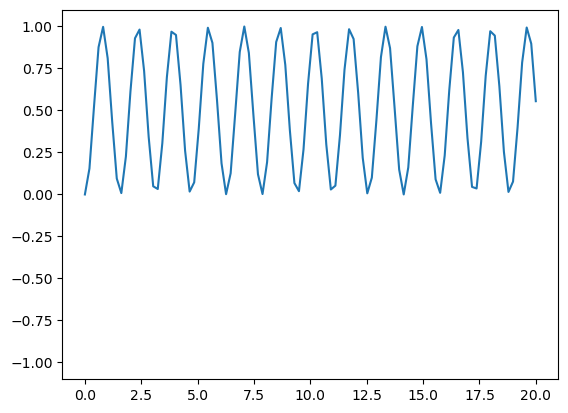

In [39]:
x = np.linspace(0, 20, 100)
fig, ax = plt.subplots()
ax.set_ylim((-1.1,1.1))
lines = ax.plot(x, np.sin(x)) # !!! data will change latter
lines[0].set_ydata(np.sin(2 * x)**2) # Change the data themselve!!!

## Error bars

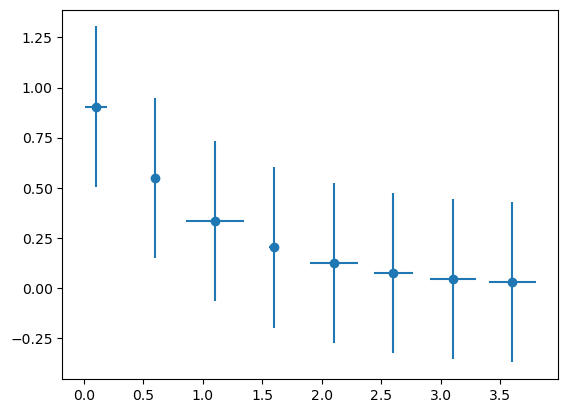

In [40]:
x = np.arange(0.1, 4, 0.5)
y = np.exp(-x)
xerr = np.random.rand(len(x))*0.3
fig, ax = plt.subplots()
eb = ax.errorbar(x, y, xerr=xerr, yerr=0.4, fmt='o');

## Sharing axes

In [41]:
%matplotlib tk
fig, axes = plt.subplots(2, sharex=True)
axes[0].plot(x, y)
axes[0].set_title('Sharing X axis')
axes[1].scatter(x, y);

In [42]:
f, (ax1, ax2) = plt.subplots(1, 2, sharey=True) # Unpacking the axes
ax1.plot(x, y)
f.suptitle('Main TITLE')
ax1.set_title('Sharing Y axis')
ax2.scatter(x, y);

In [43]:
fig, (ax1, ax2, ax3) = plt.subplots(3, sharex=True, sharey=True)
ax1.plot(x, y)
ax1.set_title('Sharing both axes')
ax2.scatter(x, y)
ax3.scatter(x, 2 * y ** 2 - 1, color='r')
# Fine-tune figure; make subplots close to each other 
fig.subplots_adjust(hspace=0)

In [43]:
%matplotlib module://matplotlib_inline.backend_inline

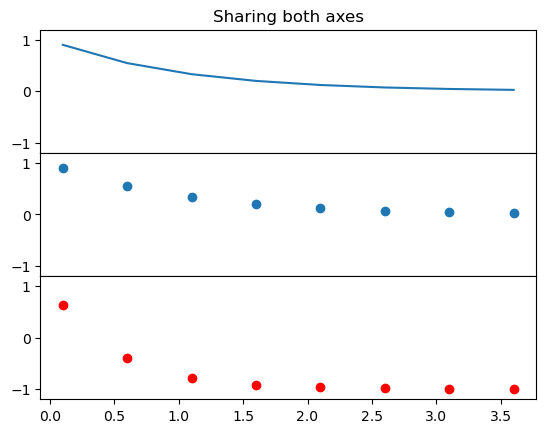

In [44]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, sharey=True)
ax1.plot(x, y)
ax1.set_title('Sharing both axes')
ax2.scatter(x, y)
ax3.scatter(x, 2 * y ** 2 - 1, color='r')
# Fine-tune figure; make subplots close to each other 
fig.subplots_adjust(hspace=0)
for ax in (ax1, ax2, ax3):
    ax.set_ylim(-1.2, 1.2)

## Histograms

(array([  9.,  37., 112., 214., 265., 206., 114.,  32.,  10.,   1.]), array([-3.02110424, -2.34483224, -1.66856025, -0.99228825, -0.31601625,
        0.36025574,  1.03652774,  1.71279974,  2.38907173,  3.06534373,
        3.74161572]), <BarContainer object of 10 artists>)


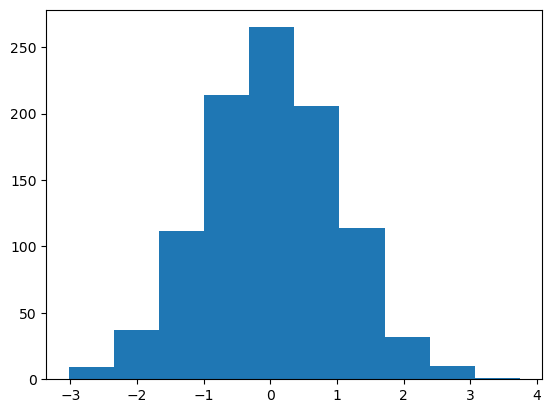

In [45]:
x = np.random.normal(size=1000)
fig, ax = plt.subplots()
H = ax.hist(x)
print(H)

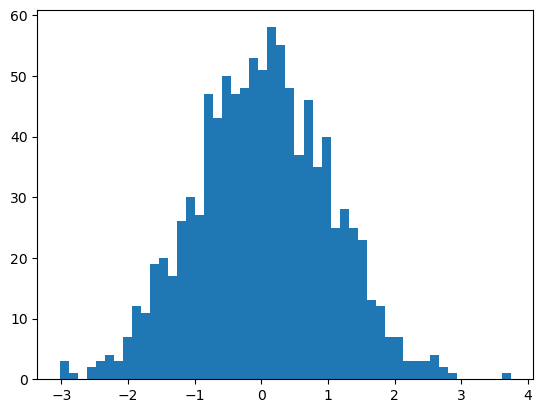

In [46]:
fig, ax = plt.subplots()
H = ax.hist(x, bins=50)

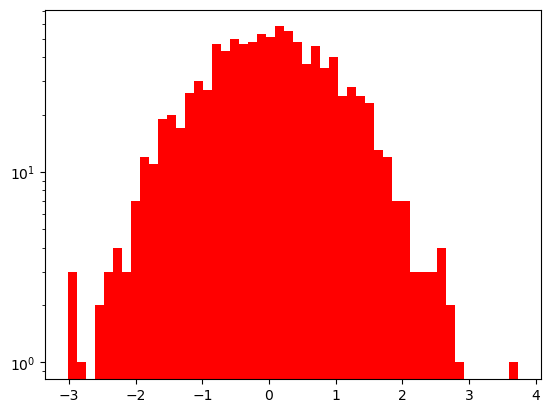

In [47]:
fig, ax = plt.subplots()
H = ax.hist(x, bins=50, histtype='stepfilled', log=True, color='r')

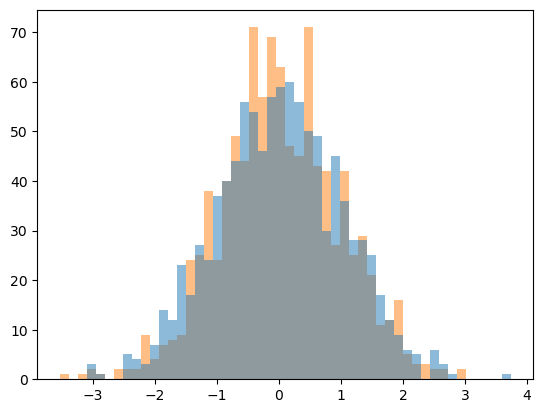

In [48]:
x2 = np.random.normal(size=1000)
fig, ax = plt.subplots()
H = ax.hist((x, x2), bins=50, alpha=.5, histtype='stepfilled')

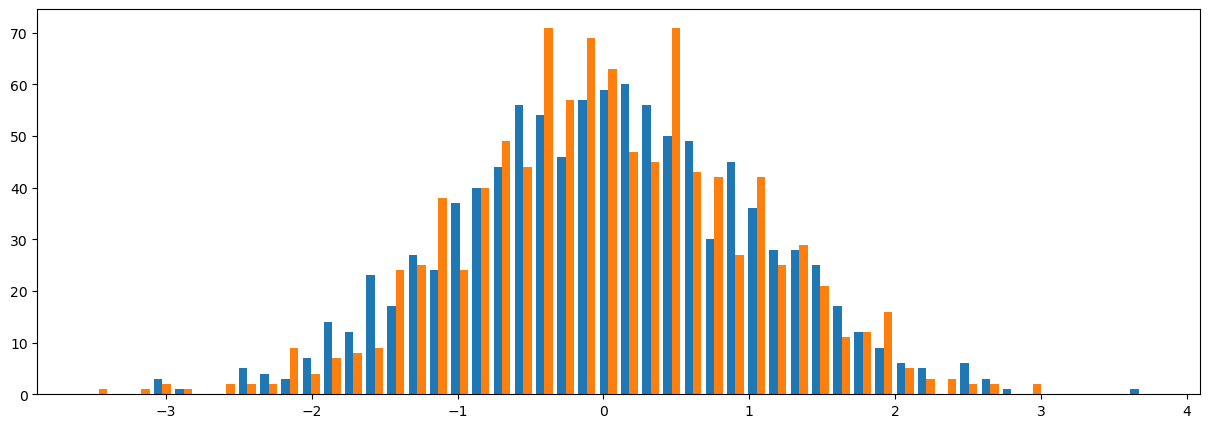

In [49]:
fig, ax = plt.subplots(figsize=(15,5))
H = ax.hist((x, x2), bins=50, histtype='bar')

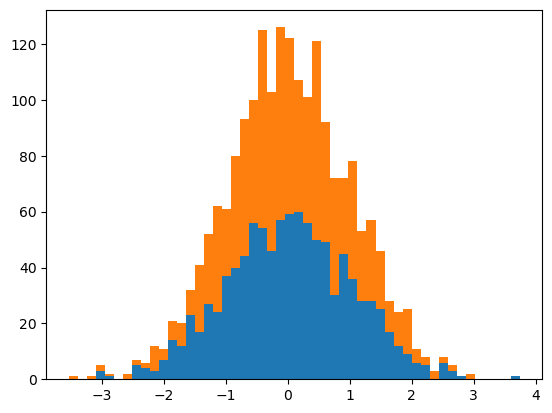

In [50]:
fig, ax = plt.subplots()
H = ax.hist((x, x2), bins=50, histtype='bar', stacked=True)

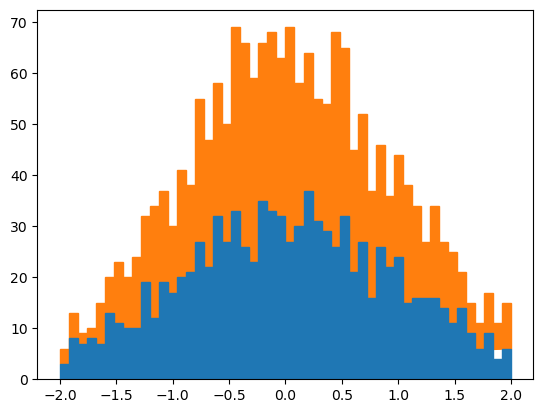

In [51]:
fig, ax = plt.subplots()
H = ax.hist((x, x2), bins=50, range=(-2, 2), histtype='step', stacked=True, fill=True)

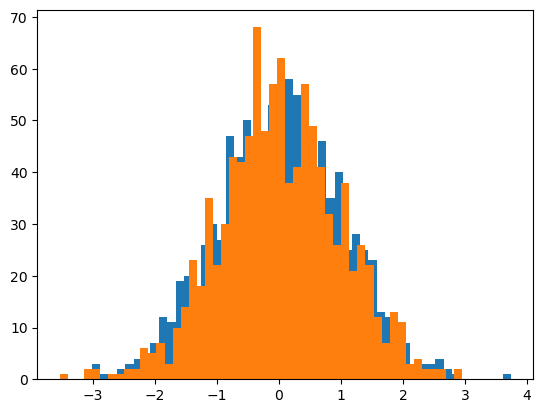

In [52]:
fig, ax = plt.subplots()
H = ax.hist(x, bins=50)
H2 = ax.hist(x2, bins=50) # !!!bins are NOT the same for both histograms!!!

(array([ 2.,  0.,  4.,  6.,  7., 17., 23., 29., 37., 43., 62., 72., 68.,
       82., 79., 81., 77., 64., 57., 50., 44., 32., 22., 16.,  9.,  4.,
        6.,  3.,  1.]), array([-3.        , -2.79310345, -2.5862069 , -2.37931034, -2.17241379,
       -1.96551724, -1.75862069, -1.55172414, -1.34482759, -1.13793103,
       -0.93103448, -0.72413793, -0.51724138, -0.31034483, -0.10344828,
        0.10344828,  0.31034483,  0.51724138,  0.72413793,  0.93103448,
        1.13793103,  1.34482759,  1.55172414,  1.75862069,  1.96551724,
        2.17241379,  2.37931034,  2.5862069 ,  2.79310345,  3.        ]), <BarContainer object of 29 artists>) (array([ 2.,  2.,  2.,  5.,  9.,  8., 14., 30., 42., 39., 58., 62., 93.,
       94., 89., 65., 83., 70., 50., 53., 39., 32., 15., 21.,  8.,  6.,
        3.,  1.,  2.]), array([-3.        , -2.79310345, -2.5862069 , -2.37931034, -2.17241379,
       -1.96551724, -1.75862069, -1.55172414, -1.34482759, -1.13793103,
       -0.93103448, -0.72413793, -0.51724138, -

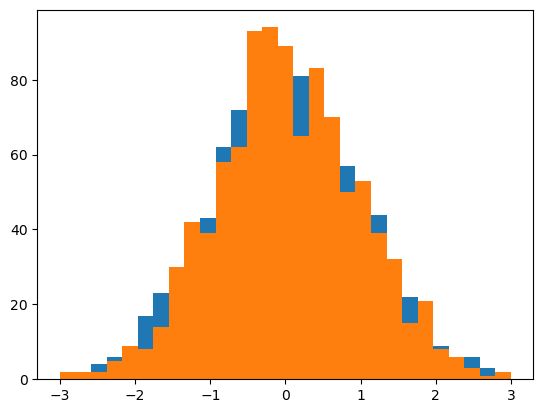

In [53]:
fig, ax = plt.subplots()
bins = np.linspace(-3, 3, 30)
H = ax.hist(x, bins=bins)
H2 = ax.hist(x2, bins=bins) # !!!bins are NOW the same for both histograms!!!
print(H, H2)

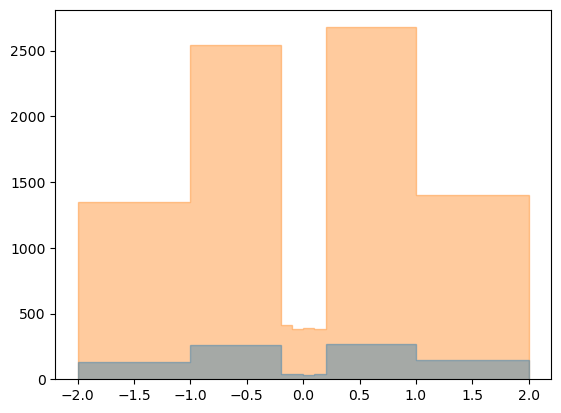

In [54]:
x2 = np.random.normal(size=10000)
fig, ax = plt.subplots()
H = ax.hist((x, x2), bins=(-2, -1, -0.2, -0.1, 0., 0.1, 0.2, 1, 2), range=(-2, 2), 
            histtype='step', alpha=0.4, fill=True)

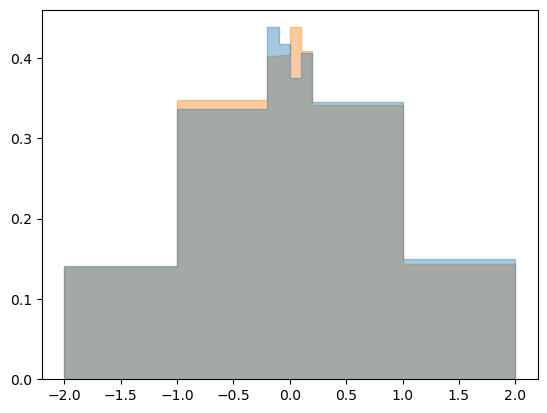

In [55]:
x2 = np.random.normal(size=10000) 
fig, ax = plt.subplots()
H = ax.hist((x, x2), bins=(-2, -1, -0.2, -0.1, 0., 0.1, 0.2, 1, 2), range=(-2, 2), 
            histtype='step', alpha=0.4, fill=True, density=True)

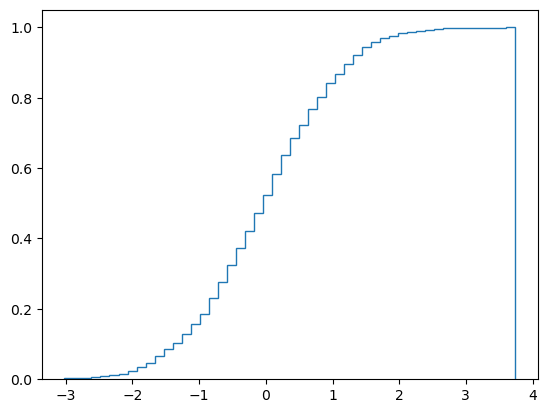

In [56]:
fig, ax = plt.subplots()
H = ax.hist(x, bins=50, histtype='step', cumulative=True, density=True)

## boxplots

In [57]:
help(ax.boxplot)

Help on method boxplot in module matplotlib.axes._axes:

boxplot(
    x,
    *,
    notch=None,
    sym=None,
    vert=None,
    orientation='vertical',
    whis=None,
    positions=None,
    widths=None,
    patch_artist=None,
    bootstrap=None,
    usermedians=None,
    conf_intervals=None,
    meanline=None,
    showmeans=None,
    showcaps=None,
    showbox=None,
    showfliers=None,
    boxprops=None,
    tick_labels=None,
    flierprops=None,
    medianprops=None,
    meanprops=None,
    capprops=None,
    whiskerprops=None,
    manage_ticks=True,
    autorange=False,
    zorder=None,
    capwidths=None,
    label=None,
    data=None
) method of matplotlib.axes._axes.Axes instance
    Draw a box and whisker plot.

    The box extends from the first quartile (Q1) to the third
    quartile (Q3) of the data, with a line at the median.
    The whiskers extend from the box to the farthest data point
    lying within 1.5x the inter-quartile range (IQR) from the box.
    Flier points a

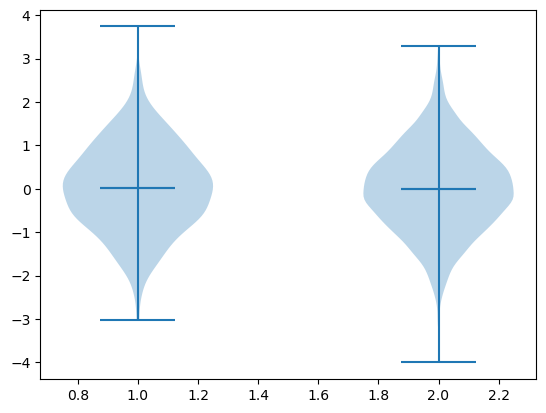

In [58]:
fig, ax = plt.subplots()
bp = ax.violinplot((x, x2), showmeans=True,showmedians=True)

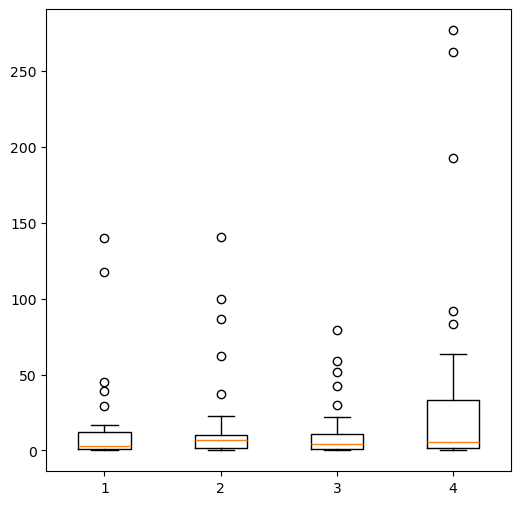

In [59]:
data = np.random.lognormal(size=(37, 4), mean=1.5, sigma=1.75)

fig, ax = plt.subplots(figsize=(6,6))
bp = ax.boxplot(data) # Nothing to see !

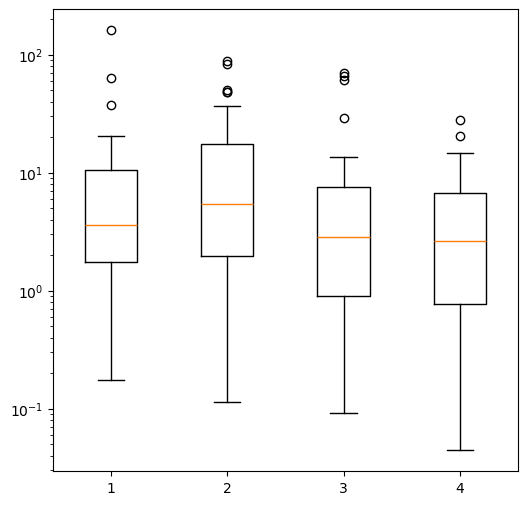

In [60]:
data = np.random.lognormal(size=(37, 4), mean=1.5, sigma=1.75)

fig, ax = plt.subplots(figsize=(6,6))
bp = ax.boxplot(data)
ax.set_yscale('log')

## Ticks, axes and spines

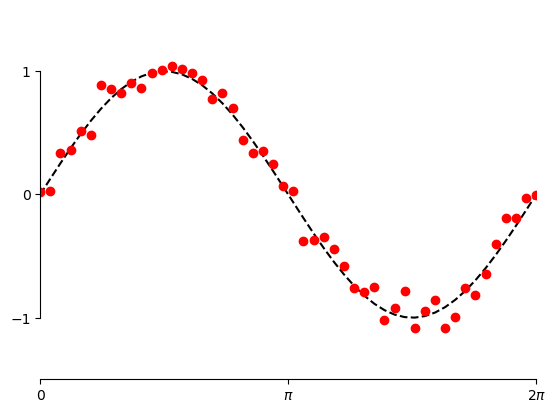

In [61]:
x = np.linspace(0, 2*np.pi, 50)
y = np.sin(x)
y2 = y + 0.1 * np.random.normal(size=x.shape) # add noise to the data

fig, ax = plt.subplots()
ax.plot(x, y, 'k--')
ax.plot(x, y2, 'ro')

# set ticks and tick labels
ax.set_xlim((0, 2*np.pi))
ax.set_xticks([0, np.pi, 2*np.pi])
ax.set_xticklabels(['0', r'$\pi$',r'2$\pi$'])
ax.set_ylim((-1.5, 1.5))
ax.set_yticks([-1, 0, 1])

# Only draw spine between the y-ticks
ax.spines['left'].set_bounds(-1, 1)
# Hide the right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
# Only show ticks on the left and bottom spines
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom');

## A plot inside a plot

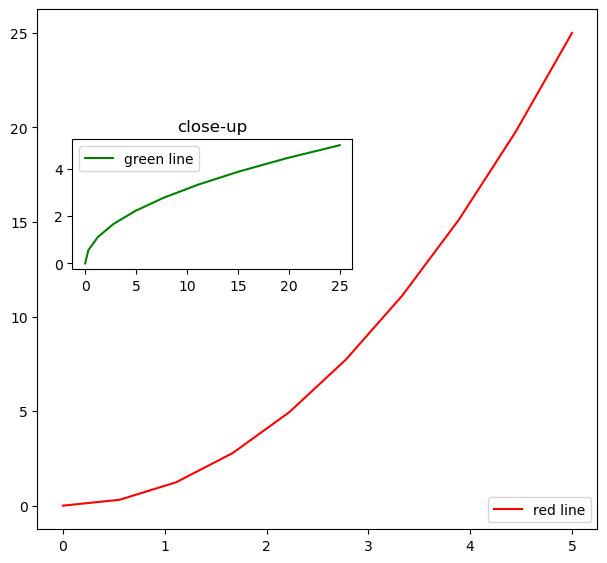

In [62]:
x = np.linspace(0, 5, 10)
y = x ** 2

fig = plt.figure(figsize=(7,6.5))

ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax2 = fig.add_axes([0.15, 0.5, 0.4, 0.2]) # inset axes

# main figure
ax1.plot(x, y, 'r', label='red line')
ax1.legend(loc=4)
# insert
ax2.plot(y, x, 'g', label = 'green line')
ax2.set_title('close-up')
ax2.legend(loc='best');

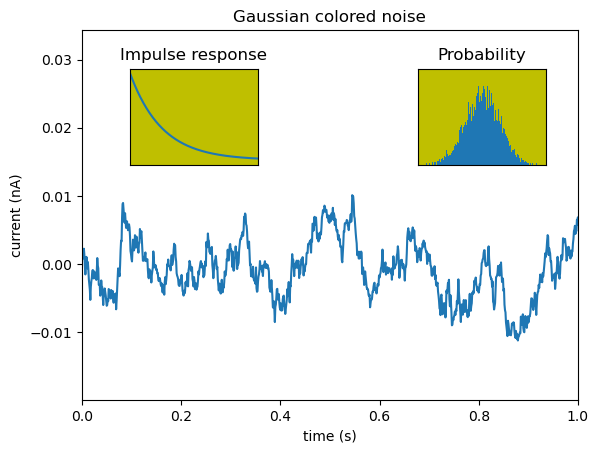

In [63]:
# The classical way

# create some data to use for the plot
dt = 0.001
t = np.arange(0.0, 10.0, dt)
r = np.exp(-t[:1000]/0.05)  # impulse response
x = np.random.randn(len(t))
s = np.convolve(x,r)[:len(x)]*dt  # colored noise

# the main axes is subplot(111) by default
plt.plot(t, s)
plt.axis([0, 1, 1.1*np.amin(s), 2*np.amax(s) ])
plt.xlabel('time (s)')
plt.ylabel('current (nA)')
plt.title('Gaussian colored noise')

# this is an inset axes over the main axes
a = plt.axes([.65, .6, .2, .2], facecolor='y')
n, bins, patches = plt.hist(s, 400, density=1)
plt.title('Probability')
plt.setp(a, xticks=[], yticks=[])

# this is another inset axes over the main axes
b = plt.axes([0.2, 0.6, .2, .2], facecolor='y')
plt.plot(t[:len(r)], r)
plt.title('Impulse response')
plt.setp(b, xlim=(0,.2), xticks=[], yticks=[]);


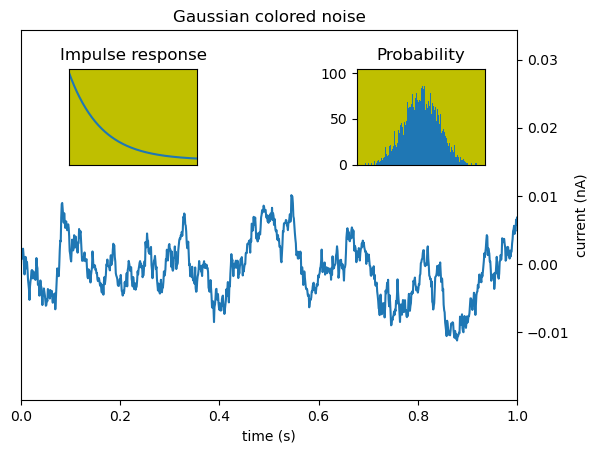

In [64]:
# The Object oriented way

# the main axes is subplot(111) by default
fig, ax = plt.subplots()
ax.plot(t, s)
ax.axis([0, 1, 1.1*np.amin(s), 2*np.amax(s) ])
# The previous command is equivalent to:
#ax.set_xlim((0., 1))
#ax.set_ylim((1.1*np.amin(s), 2*np.amax(s)))
ax.set_xlabel('time (s)')
ax.set_ylabel('current (nA)')
ax.set_title('Gaussian colored noise')
ax.yaxis.tick_right()
ax.yaxis.set_label_position("right")

# this is an inset axes over the main axes
ax2 = plt.axes([.65, .6, .2, .2], facecolor='y')
n, bins, patches = ax2.hist(s, 400, density=True)
ax2.set_title('Probability')
ax2.xaxis.set_ticks([])
#ax2.yaxis.set_ticks([])

# this is another inset axes over the main axes
ax3 = plt.axes([0.2, 0.6, .2, .2], facecolor='y')
ax3.plot(t[:len(r)], r)
ax3.set_title('Impulse response')
ax3.set_xlim((0., .2))
ax3.xaxis.set_ticks([])
ax3.yaxis.set_ticks([]);

## Play with all the objects of a plot

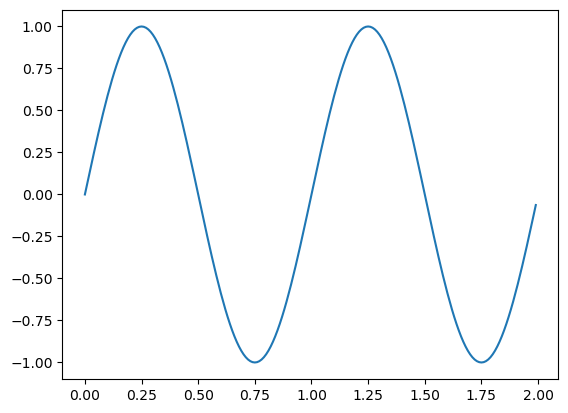

In [65]:
# Define some data
t = np.arange(0.0, 2.0, 0.01)
s = np.sin(2*np.pi*t)
fig, ax = plt.subplots()

# Plot the data and keep the data-line into an object
ax.plot(t, s);

[Text(-0.25, 0, '−0.25'), Text(0.0, 0, '0.00'), Text(0.25, 0, '0.25'), Text(0.5, 0, '0.50'), Text(0.75, 0, '0.75'), Text(1.0, 0, '1.00'), Text(1.25, 0, '1.25'), Text(1.5, 0, '1.50'), Text(1.75, 0, '1.75'), Text(2.0, 0, '2.00'), Text(2.25, 0, '2.25'), Text(0, -1.25, '−1.25'), Text(0, -1.0, '−1.00'), Text(0, -0.75, '−0.75'), Text(0, -0.5, '−0.50'), Text(0, -0.25, '−0.25'), Text(0, 0.0, '0.00'), Text(0, 0.25, '0.25'), Text(0, 0.5, '0.50'), Text(0, 0.75, '0.75'), Text(0, 1.0, '1.00'), Text(0, 1.25, '1.25'), Text(0.5, 1.0, 'Sin')]


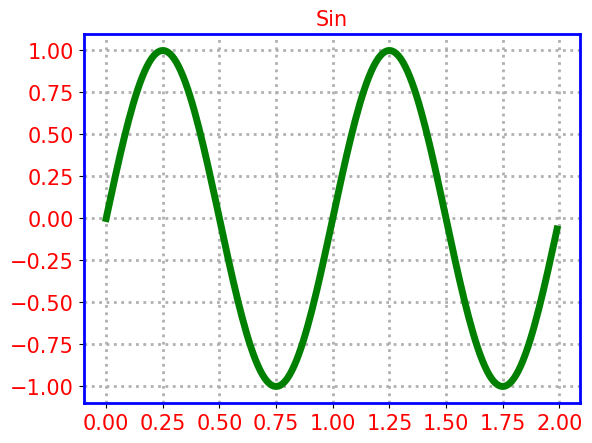

In [66]:
# Define some data
t = np.arange(0.0, 2.0, 0.01)
s = np.sin(2*np.pi*t)
fig, ax = plt.subplots()

# Plot the data and keep the data-line into an object
datalines = ax.plot(t, s)


# Plot grids on the figure
ax.grid(True)
tit = ax.set_title('Sin')

# Put all the lines and labels into lists of objects
ticklines = iter(ax.spines.values())
gridlines = ax.get_xgridlines()
gridlines.extend( ax.get_ygridlines() )
labels = ax.get_xticklabels()
labels.extend( ax.get_yticklabels() )
labels.append(tit)# Loop on the lists of lines to change properties
print(labels)

for line in ticklines:
    line.set_linewidth(2)
    line.set_color('blue')

for line in datalines:
    line.set_linewidth(5)
    line.set_color('green')

for line in gridlines:
    line.set_linestyle(':')
    line.set_linewidth(2)

# loop on the labels to change properties
for label in labels:
    label.set_color('r')
    label.set_fontsize(15)

## Changing font etc for all the plots:

In [67]:
import matplotlib
matplotlib.rcParams.update({'font.size': 18, 'font.family': 'Serif'}) # sans-serif

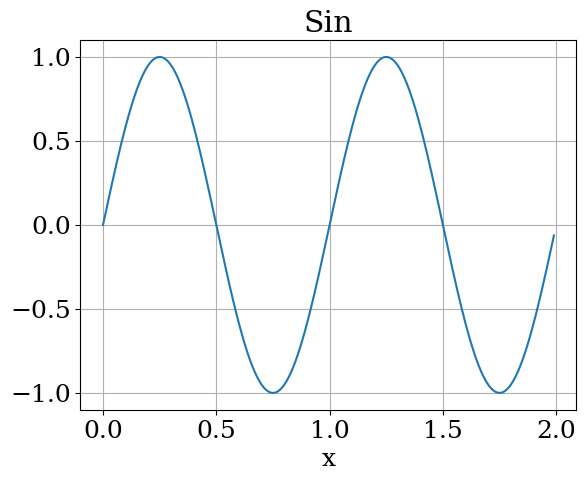

In [68]:
# Define some data
t = np.arange(0.0, 2.0, 0.01)
s = np.sin(2*np.pi*t)
fig, ax = plt.subplots()

# Plot the data and keep the data-line into an object
datalines = ax.plot(t, s)
# Plot grids on the figure
ax.grid(True)
ax.set_xlabel('x')
tit = ax.set_title('Sin')

In [69]:
# Back to default values
matplotlib.rcParams.update({'font.size': 12, 'font.family': 'sans'})

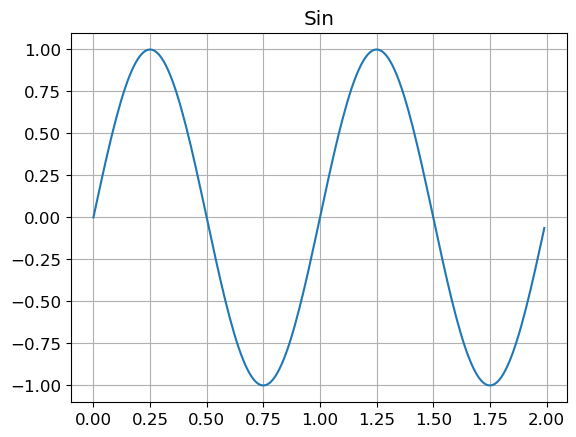

In [70]:
# Define some data
t = np.arange(0.0, 2.0, 0.01)
s = np.sin(2*np.pi*t)
fig, ax = plt.subplots()

# Plot the data and keep the data-line into an object
datalines = ax.plot(t, s)
# Plot grids on the figure
ax.grid(True)
tit = ax.set_title('Sin')

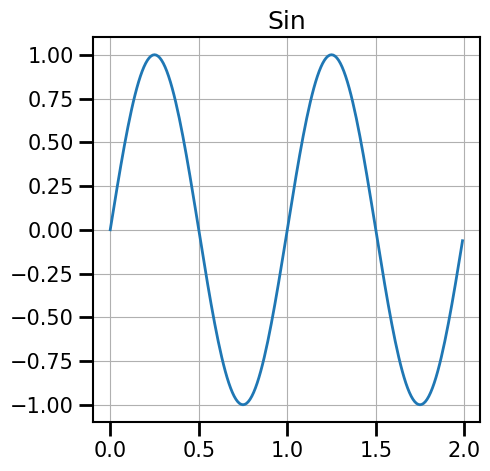

In [71]:
matplotlib.rc('axes', linewidth=1.5)
matplotlib.rc('lines', linewidth=2)
matplotlib.rc('font', size=15)
matplotlib.rc('xtick.major', width=2, size=10)
matplotlib.rc('xtick.minor', width=2, size=5)
matplotlib.rc('ytick.major', width=2, size=10)
matplotlib.rc('ytick.minor', width=2, size=5)

# Define some data
t = np.arange(0.0, 2.0, 0.01)
s = np.sin(2*np.pi*t)
fig, ax = plt.subplots(figsize=(5,5))

# Plot the data and keep the data-line into an object
datalines = ax.plot(t, s)
# Plot grids on the figure
ax.grid(True)
tit = ax.set_title('Sin')

## Twin axes

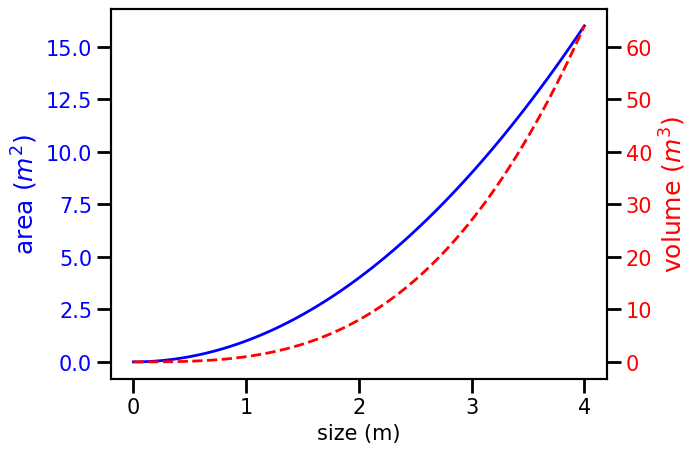

In [72]:
x = np.linspace(0, 4, 100)
fig, ax1 = plt.subplots()

ax1.plot(x, x**2, lw=2, color="blue")
ax1.set_xlabel('size (m)')
ax1.set_ylabel(r"area $(m^2)$", fontsize=18, color="blue")
for label in ax1.get_yticklabels():
    label.set_color("blue")
    
ax2 = ax1.twinx()
ax2.plot(x, x**3, lw=2, color="red", linestyle='--')
ax2.set_ylabel(r"volume $(m^3)$", fontsize=18, color="red")
for label in ax2.get_yticklabels():
    label.set_color("red")

## Axis crossing at 0

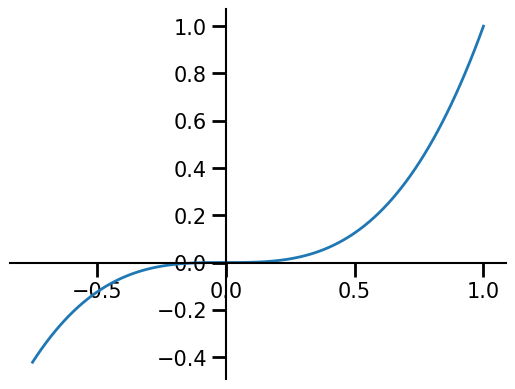

In [73]:
fig, ax = plt.subplots()

ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

ax.xaxis.set_ticks_position('bottom')
ax.spines['bottom'].set_position(('data',0)) # set position of x spine to x=0

ax.yaxis.set_ticks_position('left')
ax.spines['left'].set_position(('data',0))   # set position of y spine to y=0

xx = np.linspace(-0.75, 1., 100)
ax.plot(xx, xx**3);

## Pie plots

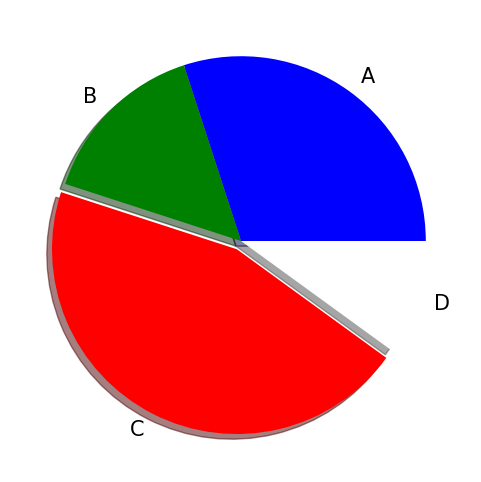

In [74]:
fracs = [30, 15, 45, 10]
colors = ['b', 'g', 'r', 'w']

fig, ax = plt.subplots(figsize=(6, 6))  # make the plot square
pie = ax.pie(fracs, colors=colors, explode=(0, 0, 0.05, 0), shadow=True,
             labels=['A', 'B', 'C', 'D'])

## Filled regions

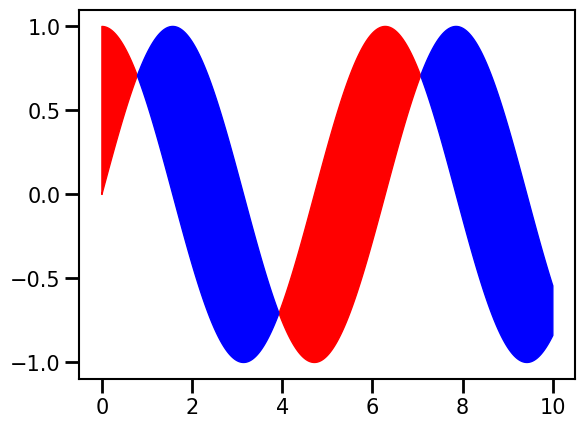

In [75]:
x = np.linspace(0, 10, 1000)
y1 = np.sin(x)
y2 = np.cos(x)

fig, ax = plt.subplots()
ax.fill_between(x, y1, y2, where=(y1 < y2), color='red')
ax.fill_between(x, y1, y2, where=(y1 > y2), color='blue');

## 2D-histograms and hexagon plots

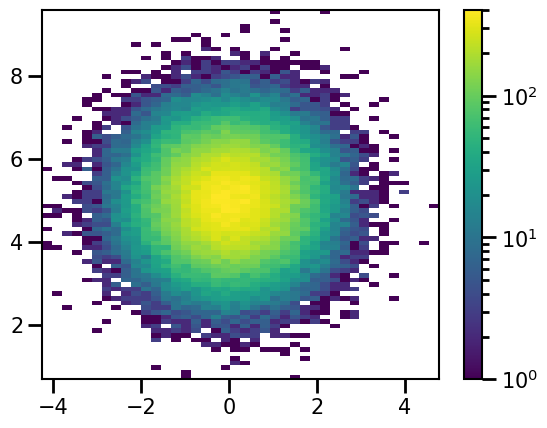

In [76]:
from matplotlib.colors import LogNorm

#normal distribution center at x=0 and y=5
x = np.random.randn(100000)
y = np.random.randn(100000)+5

fig, ax = plt.subplots()
counts, xedges, yedges, Image = ax.hist2d(x, y, bins=(40, 80), norm=LogNorm())
cb = fig.colorbar(Image)

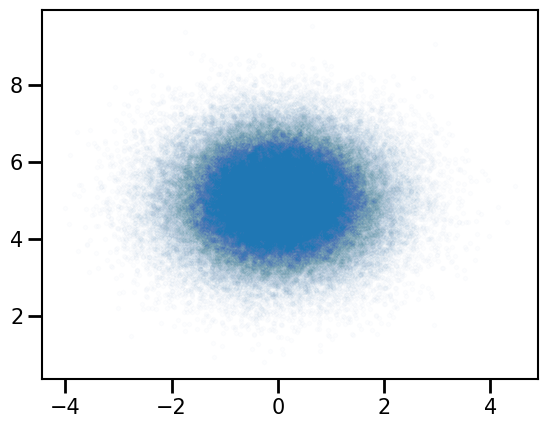

In [77]:
from matplotlib.colors import LogNorm

#normal distribution center at x=0 and y=5
x = np.random.randn(100000)
y = np.random.randn(100000)+5

fig, ax = plt.subplots()
ax.scatter(x,y, alpha=0.01, marker='.')
fig.savefig('scatter.png', dpi=100)
fig.savefig('scatter3.png', dpi=300)
fig.savefig('scatter.pdf')

In [78]:
!ls -lh scatter*

-rw-r--r--@ 1 christophemorisset  staff   1.5M Mar 24 15:23 scatter.pdf
-rw-r--r--@ 1 christophemorisset  staff   133K Mar 24 15:23 scatter.png
-rw-r--r--@ 1 christophemorisset  staff   893K Mar 24 15:23 scatter3.png


(20, 20)


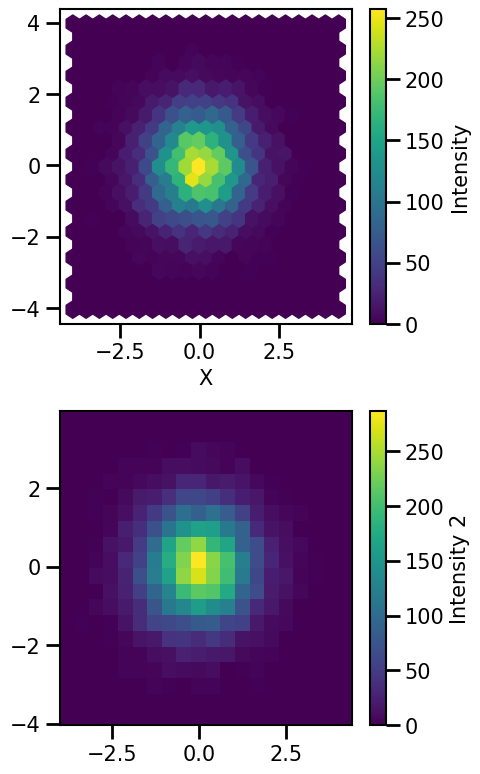

In [79]:
x, y = np.random.normal(size=(2, 10000))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5, 8))

im = ax1.hexbin(x, y, gridsize=20)
ax1.set_xlabel('X')
cb = fig.colorbar(im, ax=ax1)
cb.set_label('Intensity')

H = ax2.hist2d(x, y, bins=20)
print(H[0].shape)
cb = fig.colorbar(H[3], ax=ax2)
cb.set_label('Intensity 2')
fig.tight_layout()

## 2D data sets and Images

(100, 100)


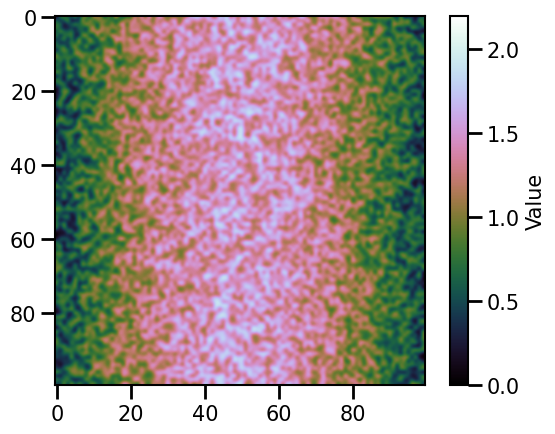

In [80]:
N = 100
I = np.random.random((N, N)) # random data in backgroud
I += np.sin(np.linspace(0, np.pi, N)) # add a sine to the data
print(I.shape)
fig, ax = plt.subplots()
im = ax.imshow(I, cmap='cubehelix', vmin=0, vmax=2.2, interpolation='bicubic') # draw the image. vmin and vmax are the limits of the colorbar
cb = fig.colorbar(im) # put the colorbar
cb.set_label('Value')

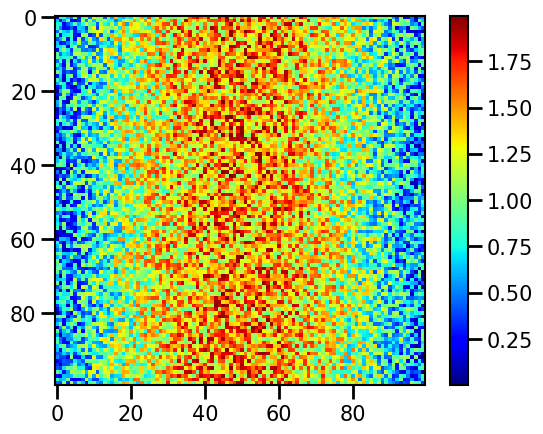

In [81]:
fig, ax = plt.subplots()
im = ax.imshow(I, cmap='jet', interpolation='none') # draw the image, no interpolations, raw data

ax = plt.gca()
fig = plt.gcf()
cb = fig.colorbar(im, ax=ax)# put the colorbar


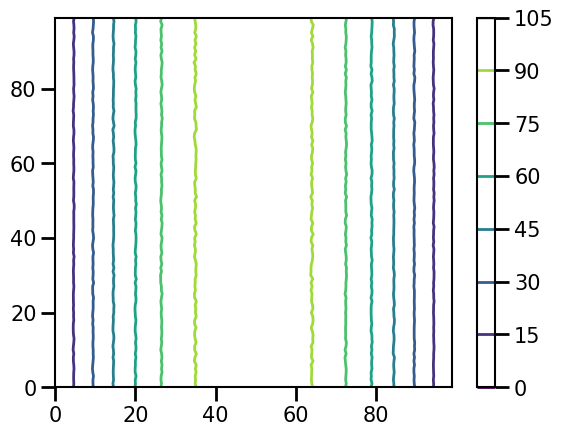

In [82]:
I = np.random.random((N, N))
I += 100*np.sin(np.linspace(0, np.pi, N))

fig, ax = plt.subplots()
ct = ax.contour(I)
cb = fig.colorbar(ct)

In [83]:
help(plt.imshow)

Help on function imshow in module matplotlib.pyplot:

imshow(
    X: 'ArrayLike | PIL.Image.Image',
    cmap: 'str | Colormap | None' = None,
    norm: 'str | Normalize | None' = None,
    *,
    aspect: "Literal['equal', 'auto'] | float | None" = None,
    interpolation: 'str | None' = None,
    alpha: 'float | ArrayLike | None' = None,
    vmin: 'float | None' = None,
    vmax: 'float | None' = None,
    colorizer: 'Colorizer | None' = None,
    origin: "Literal['upper', 'lower'] | None" = None,
    extent: 'tuple[float, float, float, float] | None' = None,
    interpolation_stage: "Literal['data', 'rgba', 'auto'] | None" = None,
    filternorm: 'bool' = True,
    filterrad: 'float' = 4.0,
    resample: 'bool | None' = None,
    url: 'str | None' = None,
    data=None,
    **kwargs
) -> 'AxesImage'
    Display data as an image, i.e., on a 2D regular raster.

    The input may either be actual RGB(A) data, or 2D scalar data, which
    will be rendered as a pseudocolor image. For displ

## Contour

(200, 2)
(100, 200) (100, 200)


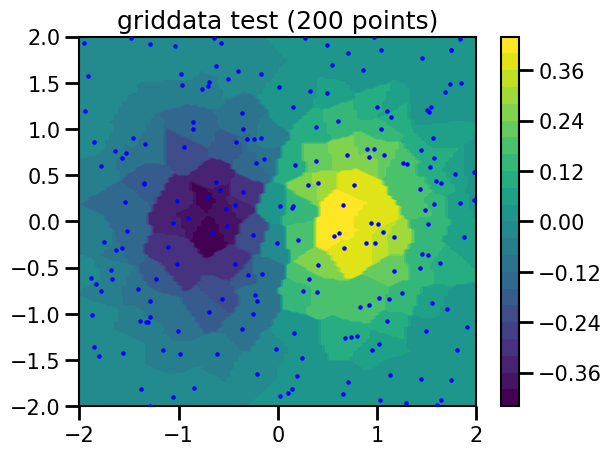

In [84]:
from scipy.interpolate import griddata

# make up data.
#npts = int(raw_input('enter # of random points to plot:'))
npts = 200
points = np.random.rand(npts, 2) * 4 - 2
x = points[:,0]
y = points[:,1]
#print(points)
def func(x,y):
    #return x*(1-x)*np.cos(4*np.pi*x) * np.sin(4*np.pi*y**2)**2
    return x * np.exp(-x**2 - y**2)
print(points.shape)
values = func(points[:,0], points[:,1])
# define grid.
xi, yi = np.mgrid[-2.1:2.1:100j, -2.1:2.1:200j]
# grid the data.
zi = griddata(points, values, (xi, yi), method='nearest') # Linear does not work???
print(xi.shape, zi.shape)
# contour the gridded data, plotting dots at the nonuniform data points.
fig, ax = plt.subplots()
CF = ax.contourf(xi, yi, zi, 25, 
                  vmax=abs(zi).max(), vmin=-abs(zi).max())
cb = fig.colorbar(CF)  # draw colorbar
# plot data points.
ax.scatter(x, y, marker='o', c='b', s=5, zorder=10)
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_title('griddata test (%d points)' % npts);

## 3D scatter plots

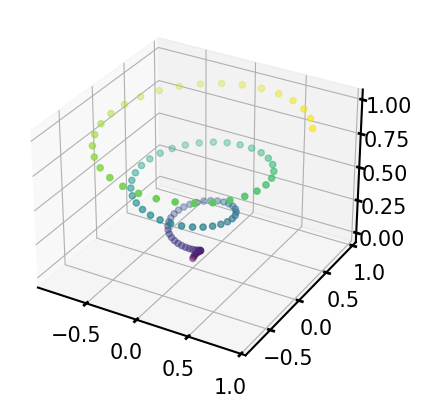

In [86]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure()
ax = plt.axes(projection='3d')

z = np.linspace(0, 1, 100)
x = z * np.sin(20 * z)
y = z * np.cos(20 * z)

c = np.sqrt(x**2 + y**2)

ax.scatter(x, y, z, c=c);
#ax.set_zscale('log')

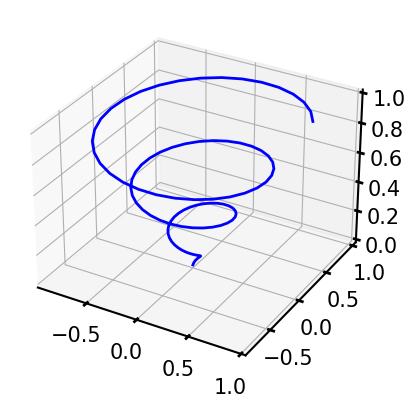

In [87]:
fig = plt.figure()
ax = plt.axes(projection='3d')

ax.plot(x, y, z, '-b')

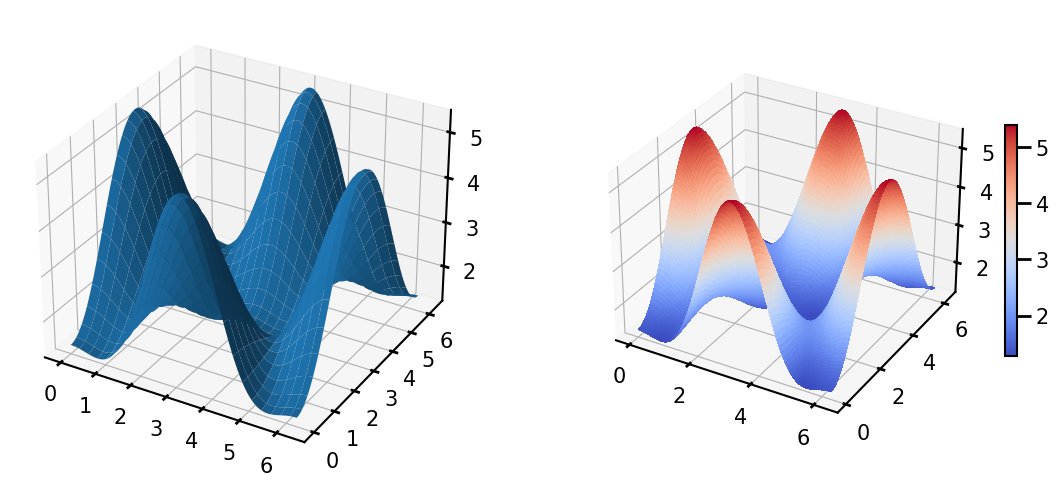

In [85]:
alpha = 0.7
phi_ext = 2 * np.pi * 0.5

def flux_qubit_potential(phi_m, phi_p):
    return 2 + alpha - 2 * np.cos(phi_p)*np.cos(phi_m) - alpha * np.cos(phi_ext - 2*phi_p)

phi_m = np.linspace(0, 2*np.pi, 100)
phi_p = np.linspace(0, 2*np.pi, 100)
X,Y = np.meshgrid(phi_p, phi_m)
Z = flux_qubit_potential(X, Y).T
fig = plt.figure(figsize=(14,6))

# `ax` is a 3D-aware axis instance, because of the projection='3d' keyword argument to add_subplot
ax = fig.add_subplot(1, 2, 1, projection='3d')

p = ax.plot_surface(X, Y, Z, rstride=4, cstride=4, linewidth=0)

# surface_plot with color grading and color bar
ax = fig.add_subplot(1, 2, 2, projection='3d')
p = ax.plot_surface(X, Y, Z, rstride=1, cstride=1, cmap=plt.cm.coolwarm, linewidth=0, 
                    antialiased=False)
cb = fig.colorbar(p, shrink=0.5)

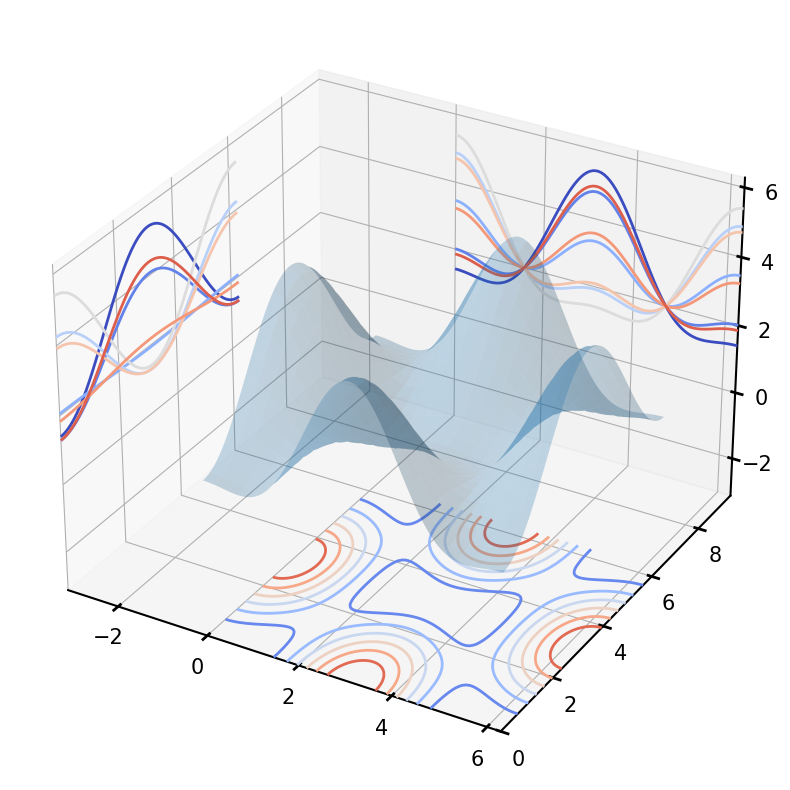

In [86]:
pi = np.pi
fig = plt.figure(figsize=(12,10))

ax = fig.add_subplot(1,1,1, projection='3d')

ax.plot_surface(X, Y, Z, rstride=4, cstride=4, alpha=0.25)
cset = ax.contour(X, Y, Z, zdir='z', offset=-pi, cmap=plt.cm.coolwarm)
cset = ax.contour(X, Y, Z, zdir='x', offset=-pi, cmap=plt.cm.coolwarm)
cset = ax.contour(X, Y, Z, zdir='y', offset=3*pi, cmap=plt.cm.coolwarm)

ax.set_xlim3d(-pi, 2*pi);
ax.set_ylim3d(0, 3*pi);
ax.set_zlim3d(-pi, 2*pi);

In [87]:
# Interactive rotating the plot
%matplotlib tk
fig = plt.figure(figsize=(12,10))

ax = fig.add_subplot(1,1,1, projection='3d')

ax.plot_surface(X, Y, Z, rstride=4, cstride=4, alpha=0.25)
cset = ax.contour(X, Y, Z, zdir='z', offset=-pi, cmap=plt.cm.coolwarm)
cset = ax.contour(X, Y, Z, zdir='x', offset=-pi, cmap=plt.cm.coolwarm)
cset = ax.contour(X, Y, Z, zdir='y', offset=3*pi, cmap=plt.cm.coolwarm)

ax.set_xlim3d(-pi, 2*pi);
ax.set_ylim3d(0, 3*pi);
ax.set_zlim3d(-pi, 2*pi);

In [88]:
%matplotlib module://matplotlib_inline.backend_inline

Other tutorials:  http://matplotlib.org/mpl_toolkits/mplot3d/tutorial.html

## Saving plots

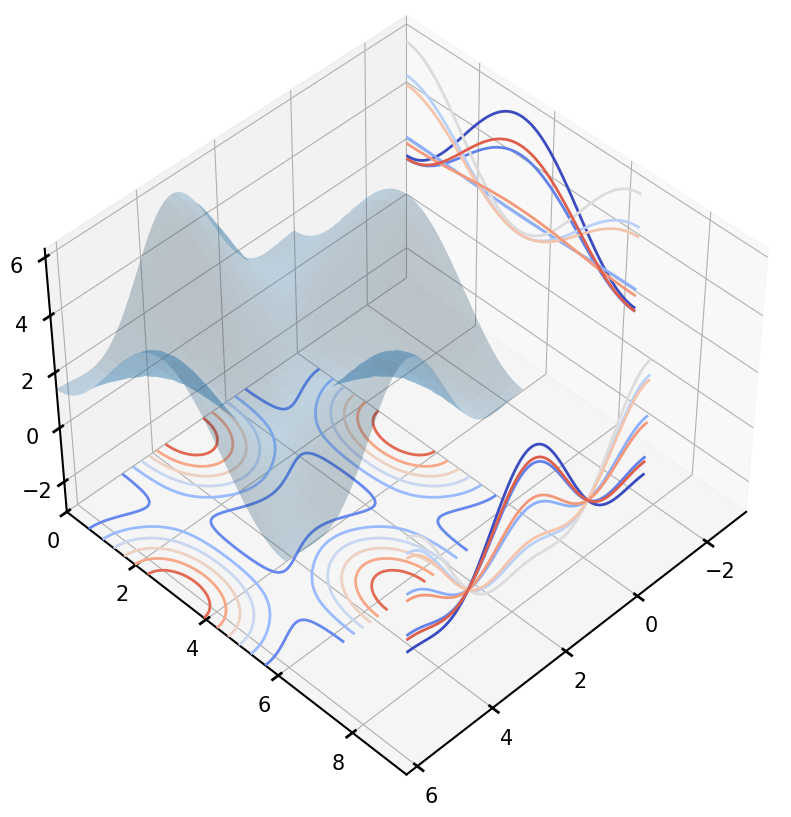

In [89]:
fig = plt.figure()

ax = fig.add_subplot(1,1,1, projection='3d')

ax.plot_surface(X, Y, Z, rstride=4, cstride=4, alpha=0.25)
cset = ax.contour(X, Y, Z, zdir='z', offset=-pi, cmap=plt.cm.coolwarm)
cset = ax.contour(X, Y, Z, zdir='x', offset=-pi, cmap=plt.cm.coolwarm)
cset = ax.contour(X, Y, Z, zdir='y', offset=3*pi, cmap=plt.cm.coolwarm)
ax.view_init(45, 45)
ax.set_xlim3d(-pi, 2*pi);
ax.set_ylim3d(0, 3*pi);
ax.set_zlim3d(-pi, 2*pi);
fig.set_size_inches(10,10)

fig.savefig('Fig1.pdf')

In [90]:
!ls *pdf

Calling Fortran.pdf     OOP.pdf                 intro_Matplotlib.pdf
Fig1.pdf                Optimization.pdf        intro_Python.pdf
Interact with files.pdf Useful_libraries.pdf    intro_Scipy.pdf
Intro_1.pdf             Using_SQLalchemy.pdf    intro_numpy.pdf
Machine Learning.pdf    Using_astropy.pdf       scatter.pdf
MySQL.pdf               Using_astroquery.pdf


## Access and clear the current figure and axe

In [91]:
fig, ax = plt.subplots()
print(plt.gca() is ax) # You can get the  current axes with gca
print(plt.gcf() is fig) # The same for the current axes. 
# But it's preferable to store them in a variable when creating
plt.clf() # clear the current figure
plt.cla() # clear the current axes
fig.clf() # clear a given figure
ax.cla(); # clear a given axes

True
True


<Figure size 640x480 with 0 Axes>

## Rasterization

https://matplotlib.org/stable/gallery/misc/rasterization_demo.html

## What's happen when not in a Notebook? plt.show() and plt.ion() commands

We are here in a Notebook, but most of the time, you will execute programs from a script or using the command line in a terminal.

When using plot, scatter or any other plotting tool, the figure will not appear when typing the command, you need to send the _plt.show()_ command to pop-up it (or them if you did more than one figure). And you will loose the interactivity with the command line! You will recover it once the figure windows are closed.

The way to change this behaviour is to call the _plt.ion()_ command (interactive On).

If you are working within an ipython session created with the --pylab option, it is done by default.


## Using alternative libraries

### Seaborns

!pip install seaborn

In [94]:
import seaborn as sns

In [95]:
fmri = sns.load_dataset("fmri") # medical data from https://github.com/mwaskom/Waskom_CerebCortex_2017
print(type(fmri))
fmri

<class 'pandas.DataFrame'>


,subject,timepoint,event,region,signal
0,s13,18,stim,parietal,-0.017552
1,s5,14,stim,parietal,-0.080883
2,s12,18,stim,parietal,-0.081033
3,s11,18,stim,parietal,-0.046134
4,s10,18,stim,parietal,-0.037970
...,...,...,...,...,...
1059,s0,8,cue,frontal,0.018165
1060,s13,7,cue,frontal,-0.029130
1061,s12,7,cue,frontal,-0.004939
1062,s11,7,cue,frontal,-0.025367


Using kind="line" offers the same flexibility for semantic mappings as kind="scatter", but lineplot() transforms the data more before plotting. Observations are sorted by their x value, and repeated observations are aggregated. By default, the resulting plot shows the mean and 95% CI for each unit.

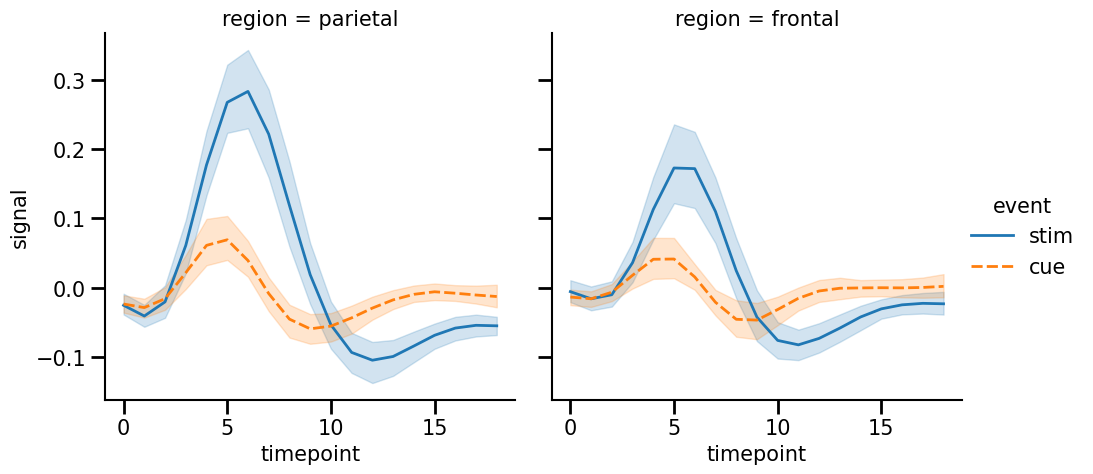

In [96]:
sns.relplot(data=fmri, kind="line",
            x="timepoint", y="signal", col="region",
            hue="event", style="event");

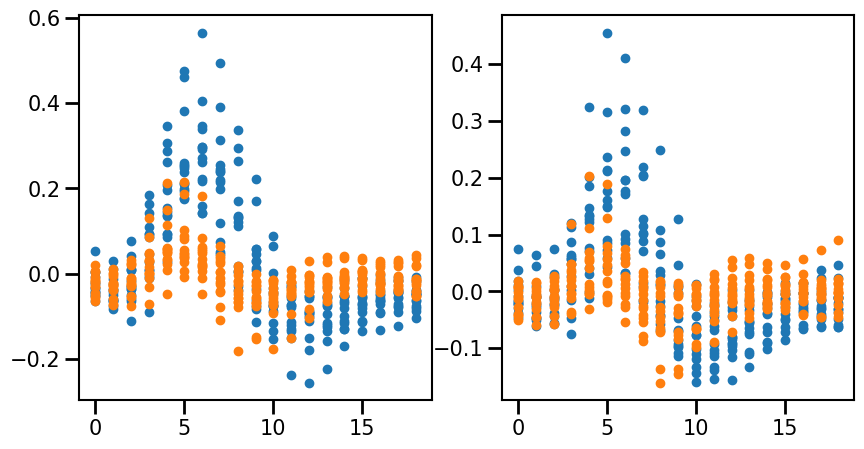

In [97]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))
mask1 = fmri['region'] == 'parietal'
mask2 = fmri['event'] == 'stim'

ax1.scatter(fmri[mask1 & mask2]['timepoint'], fmri[mask1 & mask2]['signal'])
ax1.scatter(fmri[mask1 & ~mask2]['timepoint'], fmri[mask1 & ~mask2]['signal'])

ax2.scatter(fmri[~mask1 & mask2]['timepoint'], fmri[~mask1 & mask2]['signal'])
ax2.scatter(fmri[~mask1 & ~mask2]['timepoint'], fmri[~mask1 & ~mask2]['signal']);

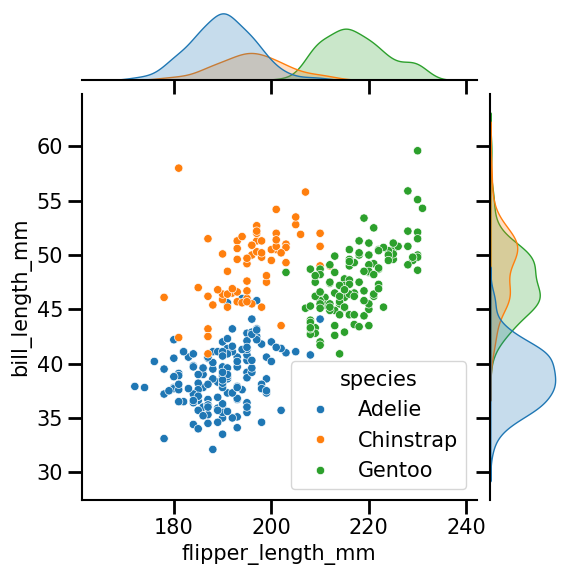

In [98]:
# From tutorial introduction on the seaborn web page:
penguins = sns.load_dataset("penguins")
sns.jointplot(data=penguins, x="flipper_length_mm", y="bill_length_mm", hue="species")

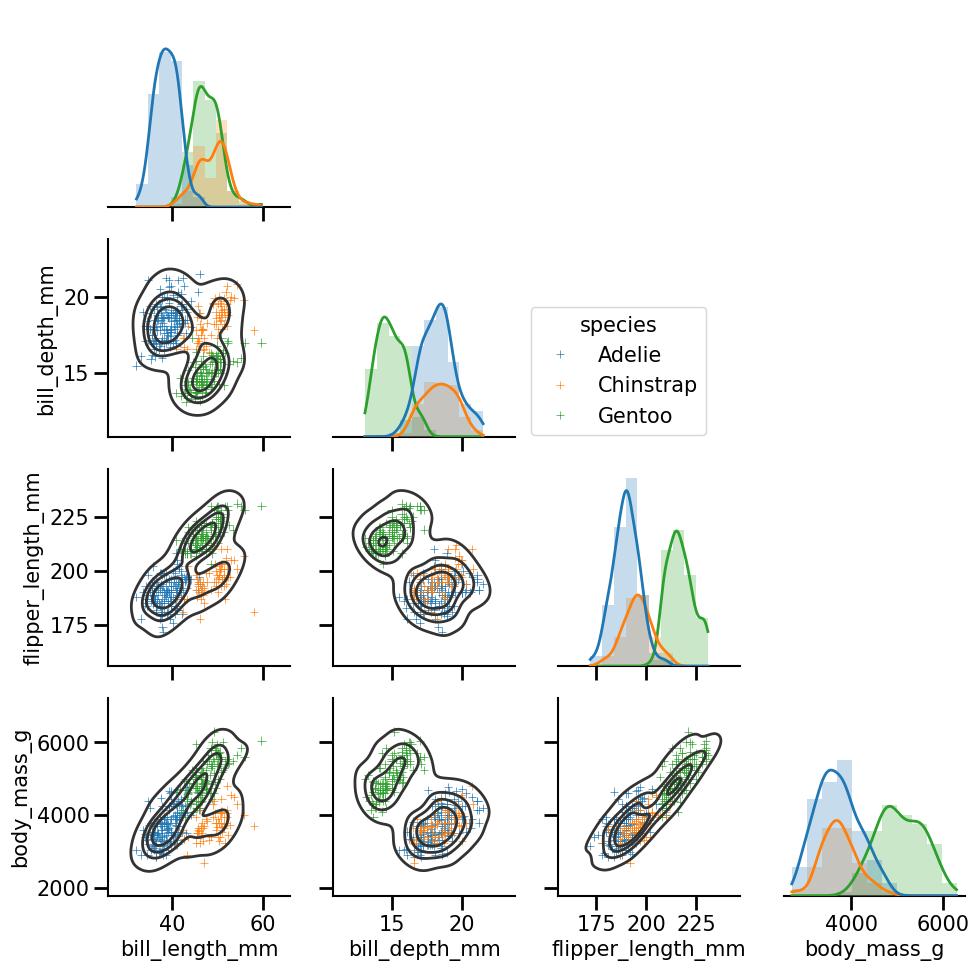

In [99]:
g = sns.PairGrid(penguins, hue="species", corner=True)
g.map_lower(sns.kdeplot, hue=None, levels=5, color=".2")
g.map_lower(sns.scatterplot, marker="+")
g.map_diag(sns.histplot, element="step", linewidth=0, kde=True)
g.add_legend(frameon=True)
g.legend.set_bbox_to_anchor((.61, .6))

### plotly

* conda install -c conda-forge plotly
* conda install -c conda-forge nbformat
* conda install -c conda-forge statsmodels

In [100]:
import plotly.graph_objects as go
import numpy as np

# Sample 3D surface plot
x = np.linspace(-5, 5, 50)
y = np.linspace(-5, 5, 50)
x, y = np.meshgrid(x, y)
z = np.sin(np.sqrt(x**2 + y**2))

fig = go.Figure(data=[go.Surface(z=z, x=x, y=y)])
fig.show()

In [103]:
import plotly.express as px
df = px.data.iris()
fig = px.scatter(df, x="sepal_width", y="sepal_length", color="species", marginal_y="violin",
           marginal_x="box", trendline="ols", template="simple_white")
fig.show()

In [102]:
import pandas as pd
import plotly.express as px

# Set the Plotly backend
pd.options.plotting.backend = "plotly"

# Sample DataFrame
df = pd.DataFrame({
    'A': [1, 2, 3],
    'B': [4, 1, 6],
    'C': [2, 3, 2]
})

# Generate a bar plot directly from the DataFrame
# This calls px.bar() under the hood
fig = df.plot.bar(title="DataFrame Bar Plot")

# Display the figure
fig.show()